### Imports

In [ ]:
from dotenv import load_dotenv
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
import requests
import seaborn as sns
from statsmodels.tsa.deterministic import CalendarFourier, DeterministicProcess

import datetime as dt
import os

load_dotenv()

True

### Loading Files & Global Variables

In [3]:
# Columns of Interest Were Identified Using Excel + Related GHCND documentation
TARGET_COLS = ["TMAX", "TMIN"]
TARGET_ATTRIBUTES_COLS = ["TMAX_ATTRIBUTES", "TMIN_ATTRIBUTES"]

TIME_COLS = ["DATE"]

WEATHER_STATS_COLS = ["AWND", "PRCP"]
WEATHER_STATS_ATTRIBUTES_COLS = ["AWND_ATTRIBUTES", "PRCP_ATTRIBUTES"]

WIND_COLS = [
    "WDF1", "WDFG", "WDF2", "WDF5",
    "WSF1", "WSFG", "WSF2", "WSF5"
]
WIND_ATTRIBUTES_COLS = [
    "WDF1_ATTRIBUTES", "WDFG_ATTRIBUTES", "WDF2_ATTRIBUTES", "WDF5_ATTRIBUTES",
    "WSF1_ATTRIBUTES", "WSFG_ATTRIBUTES", "WSF2_ATTRIBUTES", "WSF5_ATTRIBUTES"
]

WEATHER_TYPE_COLS = [
    "WT01", "WT02", "WT03", "WT04", "WT05", "WT06",
    "WT07", "WT08", "WT09", "WT10", "WT11", "WT13",
    "WT14", "WT15", "WT16", "WT18", "WT21", "WV03"
]
WEATHER_TYPE_ATTRIBUTES_COLS = [
    "WT01_ATTRIBUTES", "WT02_ATTRIBUTES", "WT03_ATTRIBUTES", "WT04_ATTRIBUTES", "WT05_ATTRIBUTES", "WT06_ATTRIBUTES",
    "WT07_ATTRIBUTES", "WT08_ATTRIBUTES", "WT09_ATTRIBUTES", "WT10_ATTRIBUTES", "WT11_ATTRIBUTES", "WT13_ATTRIBUTES",
    "WT14_ATTRIBUTES", "WT15_ATTRIBUTES", "WT16_ATTRIBUTES", "WT18_ATTRIBUTES", "WT21_ATTRIBUTES", "WV03_ATTRIBUTES"
]

# OpenWeather API Information
OPENWEATHER_API_KEY = os.environ["OPENWEATHER_API_KEY"]
TPA_LAT = 27.96139
TPA_LON = -82.54028

In [4]:
# Load GHCND Data
ghcnd_df = pd.read_csv(r"../data/raw/GHCND_1980_to_2026.csv")
ghcnd_df["DATE"] = pd.to_datetime(ghcnd_df["DATE"])

C:\Users\Moral\AppData\Local\Temp\ipykernel_24416\2506774356.py:2: DtypeWarning: Columns (7: ACMH_ATTRIBUTES, 9: ACSH_ATTRIBUTES, 13: FMTM_ATTRIBUTES, 19: PSUN_ATTRIBUTES, 25: TAVG_ATTRIBUTES, 31: TSUN_ATTRIBUTES, 33: WDF1_ATTRIBUTES, 39: WDFG_ATTRIBUTES, 41: WESD_ATTRIBUTES, 43: WSF1_ATTRIBUTES, 49: WSFG_ATTRIBUTES, 57: WT04_ATTRIBUTES, 59: WT05_ATTRIBUTES, 61: WT06_ATTRIBUTES, 63: WT07_ATTRIBUTES, 67: WT09_ATTRIBUTES, 69: WT10_ATTRIBUTES, 71: WT11_ATTRIBUTES, 73: WT13_ATTRIBUTES, 75: WT14_ATTRIBUTES, 77: WT15_ATTRIBUTES, 79: WT16_ATTRIBUTES, 81: WT18_ATTRIBUTES, 83: WT21_ATTRIBUTES, 85: WV03_ATTRIBUTES) have mixed types. Specify dtype option on import or set low_memory=False.
  ghcnd_df = pd.read_csv(r"../data/raw/GHCND_1980_to_2026.csv")


### Column Analysis

#### Time
- No days from 1980 to 2025 are not represented. Somedays in 2026 are missing due to the data being collected in the latter end of 2026.

In [5]:
def plot_periodogram(ts, detrend='linear', ax=None):
    from scipy.signal import periodogram
    fs = pd.Timedelta("365D") / pd.Timedelta("1D")
    freqencies, spectrum = periodogram(
        ts,
        fs=fs,
        detrend=detrend,
        window="boxcar",
        scaling='spectrum',
    )
    if ax is None:
        _, ax = plt.subplots()
    ax.step(freqencies, spectrum, color="purple")
    ax.set_xscale("log")
    ax.set_xticks([1, 2, 4, 6, 12, 26, 52, 104])
    ax.set_xticklabels(
        [
            "Annual (1)",
            "Semiannual (2)",
            "Quarterly (4)",
            "Bimonthly (6)",
            "Monthly (12)",
            "Biweekly (26)",
            "Weekly (52)",
            "Semiweekly (104)",
        ],
        rotation=30,
    )
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.set_ylabel("Variance")
    ax.set_title("Periodogram")
    return ax

In [6]:
ghcnd_df[TIME_COLS].info()

<class 'pandas.DataFrame'>
RangeIndex: 17093 entries, 0 to 17092
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   DATE    17093 non-null  datetime64[us]
dtypes: datetime64[us](1)
memory usage: 133.7 KB


In [7]:
ghcnd_df[TIME_COLS].describe()

,DATE
count,17093
mean,2003-05-26 00:00:00
min,1980-01-01 00:00:00
25%,1991-09-13 00:00:00
50%,2003-05-26 00:00:00
75%,2015-02-05 00:00:00
max,2026-10-18 00:00:00


In [8]:
ghcnd_df[TIME_COLS].head()

,DATE
0,1980-01-01
1,1980-01-02
2,1980-01-03
3,1980-01-04
4,1980-01-05


In [9]:
ghcnd_df["YEAR"] = ghcnd_df[TIME_COLS].map(
    lambda x: x.year
)
ghcnd_df["MONTH"] = ghcnd_df[TIME_COLS].map(
    lambda x: x.month
)
ghcnd_df["DAY"] = ghcnd_df[TIME_COLS].map(
    lambda x: x.day
)
ghcnd_df["DAY_OF_YEAR"] = ghcnd_df["DATE"].map(
    lambda x: int(x.strftime('%j'))
)

In [10]:
ghcnd_df[TIME_COLS + ["YEAR", "MONTH", "DAY"]].groupby(by="YEAR")["DATE"].count().filter(lambda x: x < 365)

YEAR
2026    291
Name: DATE, dtype: int64

In [67]:
tunnel = ghcnd_df[TIME_COLS + TARGET_COLS].set_index("DATE").to_period("D").interpolate("time")

<Axes: title={'center': 'Periodogram'}, ylabel='Variance'>

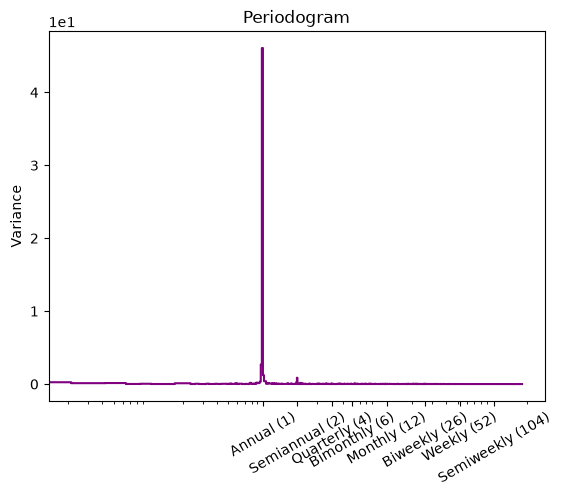

In [68]:
plot_periodogram(tunnel.TMAX)

<Axes: title={'center': 'Periodogram'}, ylabel='Variance'>

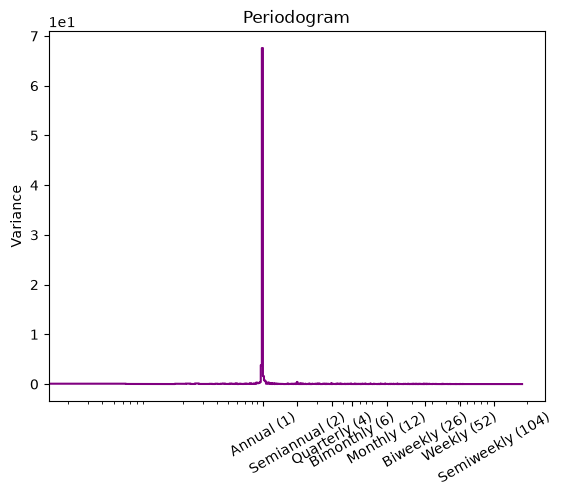

In [69]:
plot_periodogram(tunnel.TMIN)

In [87]:
fourier = CalendarFourier(freq="YE", order=1)
dp = DeterministicProcess(
    index=tunnel.index,
    constant=False,
    order=0,
    additional_terms=[fourier],
    drop=True
)

In [82]:
dp.out_of_sample(steps=79)

,"sin(1,freq=YE-DEC)","cos(1,freq=YE-DEC)"
2026-10-19,-0.956235,0.292600
2026-10-20,-0.951057,0.309017
2026-10-21,-0.945596,0.325342
2026-10-22,-0.939856,0.341571
2026-10-23,-0.933837,0.357698
...,...,...
2027-01-01,0.000000,1.000000
2027-01-02,0.017213,0.999852
2027-01-03,0.034422,0.999407
2027-01-04,0.051620,0.998667


In [78]:
from math import sin, cos, pi

In [84]:
sin(2*pi*(1/365)*2), cos(2*pi*(1/365)*2)

(0.03442161162274574, 0.9994074007397048)

#### TMAX/TMIN
- Original data null in 2019-06-26 (Record Hot Day), 2019-06-27 (Record Hot Day), 2019-08-01 (Just Missing), 2024-10-10 (Hurricane Milton)
    - Replace with some sort of interpolation

In [34]:
ghcnd_df[TIME_COLS + TARGET_COLS + TARGET_ATTRIBUTES_COLS].head()

,DATE,TMAX,TMIN,TMAX_ATTRIBUTES,TMIN_ATTRIBUTES
0,1980-01-01,60.0,44.0,",,0",",,0"
1,1980-01-02,61.0,37.0,",,0",",,0"
2,1980-01-03,67.0,35.0,",,0",",,0"
3,1980-01-04,66.0,51.0,",,0",",,0"
4,1980-01-05,60.0,44.0,",,0",",,0"


In [35]:
ghcnd_df[TIME_COLS + TARGET_COLS].info()

<class 'pandas.DataFrame'>
RangeIndex: 17093 entries, 0 to 17092
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   DATE    17093 non-null  datetime64[us]
 1   TMAX    17091 non-null  float64       
 2   TMIN    17090 non-null  float64       
dtypes: datetime64[us](1), float64(2)
memory usage: 400.7 KB


In [36]:
ghcnd_df[TIME_COLS + TARGET_COLS].describe()

,DATE,TMAX,TMIN
count,17093,17091.000000,17090.000000
mean,2003-05-26 00:00:00,82.536832,65.429374
min,1980-01-01 00:00:00,38.000000,19.000000
25%,1991-09-13 00:00:00,77.000000,58.000000
50%,2003-05-26 00:00:00,85.000000,68.000000
75%,2015-02-05 00:00:00,90.000000,74.000000
max,2026-10-18 00:00:00,100.000000,85.000000
std,NaN,9.084950,10.963633


In [37]:
ghcnd_df[ghcnd_df.TMAX.isnull() | ghcnd_df.TMIN.isnull() | (ghcnd_df.TMAX == 9999) | (ghcnd_df.TMIN == 9999)][TIME_COLS + TARGET_COLS + TARGET_ATTRIBUTES_COLS]

,DATE,TMAX,TMIN,TMAX_ATTRIBUTES,TMIN_ATTRIBUTES
14421,2019-06-26,96.0,NaN,",,W",NaN
14422,2019-06-27,93.0,NaN,",,W",NaN
14457,2019-08-01,NaN,73.0,NaN,",,W"
16354,2024-10-10,NaN,NaN,NaN,NaN


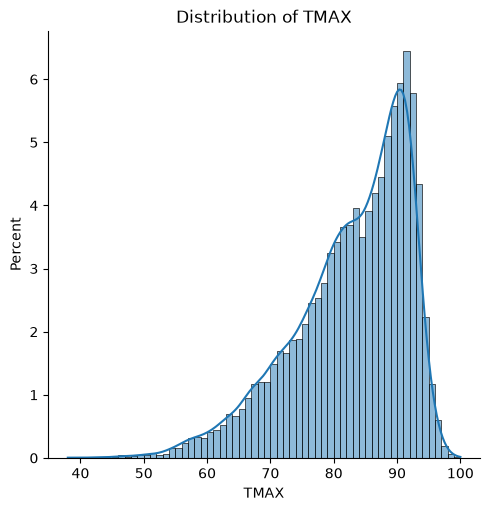

In [38]:
g = sns.displot(data=ghcnd_df, x="TMAX", kde=True, stat="percent")
g.ax.set_title("Distribution of TMAX")
plt.show()

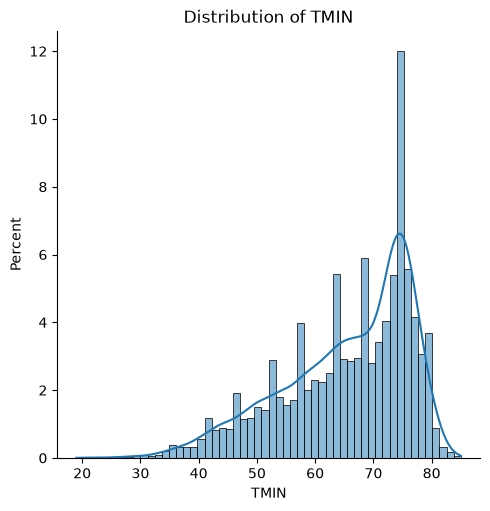

In [39]:
g = sns.displot(data=ghcnd_df, x="TMIN", kde=True, stat="percent")
g.ax.set_title("Distribution of TMIN")
plt.show()

C:\Users\Moral\AppData\Local\Temp\ipykernel_52464\3235020201.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


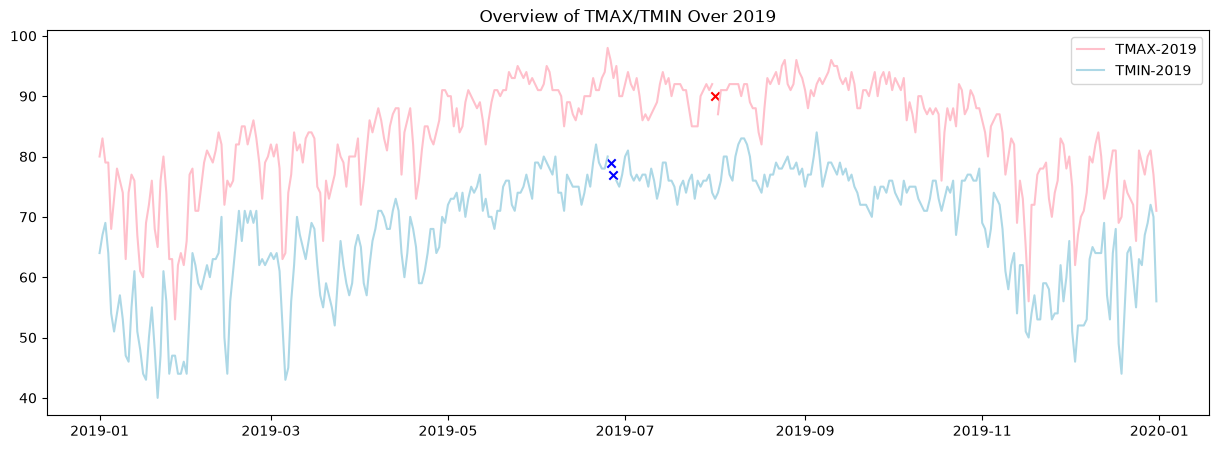

In [40]:
fig, axs = plt.subplots(1, 1, figsize=(15, 5))

axs.plot(ghcnd_df[ghcnd_df.YEAR == 2019]["DATE"], ghcnd_df[ghcnd_df.YEAR == 2019]["TMAX"], label="TMAX-2019", color="pink")
axs.scatter(ghcnd_df[(ghcnd_df.YEAR == 2019) & (ghcnd_df.TMAX.isna())]["DATE"], 90, c="red", marker="x")

axs.plot(ghcnd_df[ghcnd_df.YEAR == 2019]["DATE"], ghcnd_df[ghcnd_df.YEAR == 2019]["TMIN"], label="TMIN-2019", color="lightblue")
axs.scatter(ghcnd_df[(ghcnd_df.YEAR == 2019) & (ghcnd_df.TMIN.isna())]["DATE"], [79,77], c="blue", marker="x")

axs.set_title("Overview of TMAX/TMIN Over 2019")
axs.legend()
fig.show()

C:\Users\Moral\AppData\Local\Temp\ipykernel_52464\2557772613.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs.legend()
C:\Users\Moral\AppData\Local\Temp\ipykernel_52464\2557772613.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


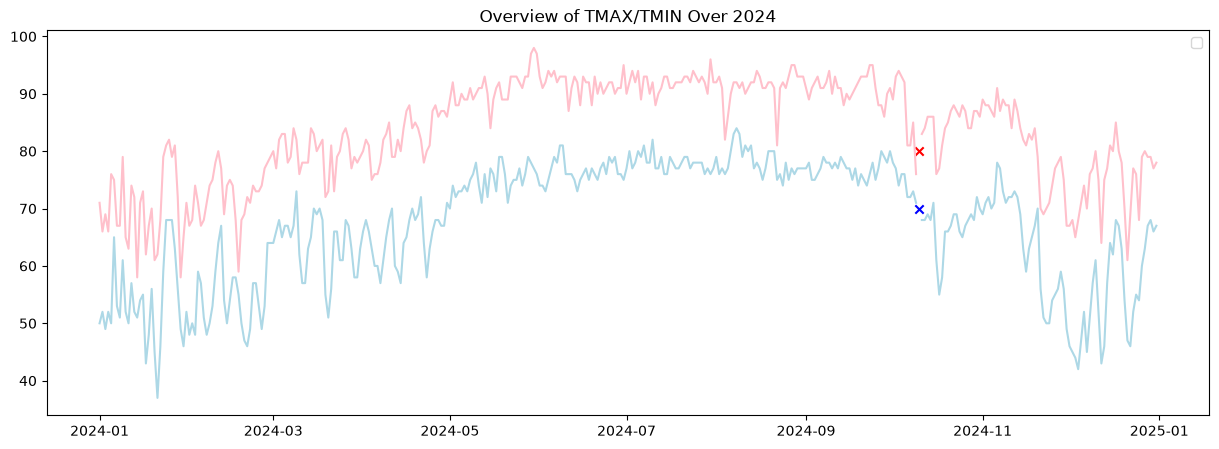

In [41]:
fig, axs = plt.subplots(1, 1, figsize=(15, 5))

axs.plot(ghcnd_df[ghcnd_df.YEAR == 2024]["DATE"], ghcnd_df[ghcnd_df.YEAR == 2024]["TMAX"], color="pink")
axs.scatter(ghcnd_df[(ghcnd_df.YEAR == 2024) & (ghcnd_df.TMAX.isna())]["DATE"], 80, c="red", marker="x")
axs.plot(ghcnd_df[ghcnd_df.YEAR == 2024]["DATE"], ghcnd_df[ghcnd_df.YEAR == 2024]["TMIN"], color="lightblue")
axs.scatter(ghcnd_df[(ghcnd_df.YEAR == 2024) & (ghcnd_df.TMAX.isna())]["DATE"], 70, c="blue", marker="x")

axs.set_title("Overview of TMAX/TMIN Over 2024")
axs.legend()
fig.show()

In [42]:
ghcnd_df["TMAX_lag1"] = ghcnd_df["TMAX"].shift(1)
ghcnd_df["TMAX_lag2"] = ghcnd_df["TMAX"].shift(2)
ghcnd_df["TMAX_lag3"] = ghcnd_df["TMAX"].shift(3)

ghcnd_df["TMIN_lag1"] = ghcnd_df["TMIN"].shift(1)
ghcnd_df["TMIN_lag2"] = ghcnd_df["TMIN"].shift(2)
ghcnd_df["TMIN_lag3"] = ghcnd_df["TMIN"].shift(3)

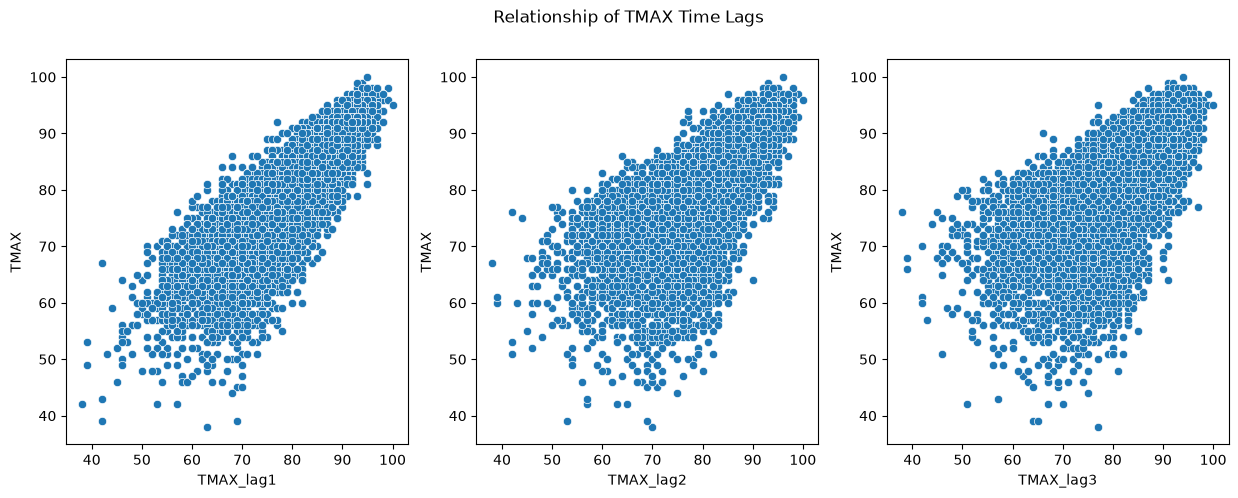

In [43]:
fig, axs = plt.subplots(1, 3, figsize=(15,5))

sns.scatterplot(data=ghcnd_df, x="TMAX_lag1", y="TMAX", ax=axs[0])
sns.scatterplot(data=ghcnd_df, x="TMAX_lag2", y="TMAX", ax=axs[1])
sns.scatterplot(data=ghcnd_df, x="TMAX_lag3", y="TMAX", ax=axs[2])

fig.suptitle("Relationship of TMAX Time Lags")

plt.show()

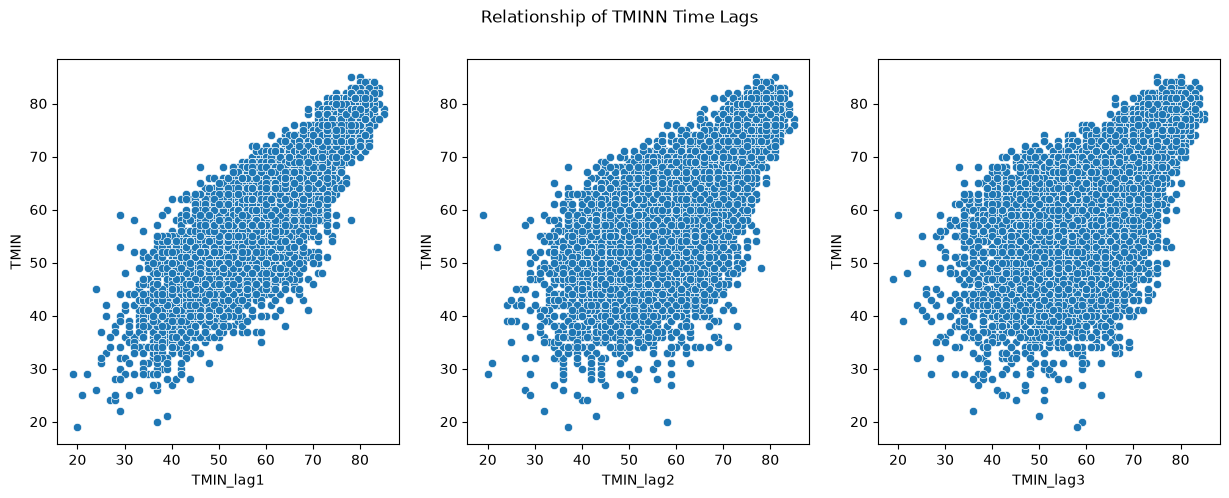

In [44]:
fig, axs = plt.subplots(1, 3, figsize=(15,5))

sns.scatterplot(data=ghcnd_df, x="TMIN_lag1", y="TMIN", ax=axs[0])
sns.scatterplot(data=ghcnd_df, x="TMIN_lag2", y="TMIN", ax=axs[1])
sns.scatterplot(data=ghcnd_df, x="TMIN_lag3", y="TMIN", ax=axs[2])

fig.suptitle("Relationship of TMINN Time Lags")

plt.show()

#### AWND/PRCP
- AWND:
    - Not found in 1980, 1981, 1982, or 1983. Only 2 days in 1997 and 1 day in 2022 are missing AWND
    - I will consider dropping 1980, 1981, and 1982 plus fill in 1997 and 2022 with interpolation like with TMAX and TMIN or drop it in production.
    - Lag features have no noticeable linear relationship with TMAX/TMIN, however, low winds correspond to lower temperatures
- PRCP:
    - Found throughout the dataset, but may be hard to recreate/recollect in prodcution
    - Lag features have no noticeable linear relationship with TMAX/TMIN, however, low winds correspond to lower temperatures


In [45]:
ghcnd_df[TIME_COLS + WEATHER_STATS_COLS].head()

,DATE,AWND,PRCP
0,1980-01-01,NaN,0.00
1,1980-01-02,NaN,0.00
2,1980-01-03,NaN,0.00
3,1980-01-04,NaN,0.11
4,1980-01-05,NaN,0.00


In [46]:
ghcnd_df[TIME_COLS + WEATHER_STATS_COLS].info()

<class 'pandas.DataFrame'>
RangeIndex: 17093 entries, 0 to 17092
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   DATE    17093 non-null  datetime64[us]
 1   AWND    15629 non-null  float64       
 2   PRCP    17093 non-null  float64       
dtypes: datetime64[us](1), float64(2)
memory usage: 400.7 KB


In [47]:
ghcnd_df[TIME_COLS + WEATHER_STATS_COLS].describe()

,DATE,AWND,PRCP
count,17093,15629.000000,17093.000000
mean,2003-05-26 00:00:00,6.805078,0.133930
min,1980-01-01 00:00:00,0.000000,0.000000
25%,1991-09-13 00:00:00,5.140000,0.000000
50%,2003-05-26 00:00:00,6.490000,0.000000
75%,2015-02-05 00:00:00,8.050000,0.030000
max,2026-10-18 00:00:00,29.080000,11.430000
std,NaN,2.392886,0.422862


In [48]:
ghcnd_df["AWND_lag1"] = ghcnd_df["AWND"].shift(1)
ghcnd_df["AWND_lag2"] = ghcnd_df["AWND"].shift(2)
ghcnd_df["AWND_lag3"] = ghcnd_df["AWND"].shift(3)

ghcnd_df["PRCP_lag1"] = ghcnd_df["PRCP"].shift(1)
ghcnd_df["PRCP_lag2"] = ghcnd_df["PRCP"].shift(2)
ghcnd_df["PRCP_lag3"] = ghcnd_df["PRCP"].shift(3)

In [49]:
ghcnd_df[ghcnd_df.AWND.isnull()].groupby(by="YEAR")["DATE"].count()

YEAR
1980    366
1981    365
1982    365
1983    365
1997      2
2022      1
Name: DATE, dtype: int64

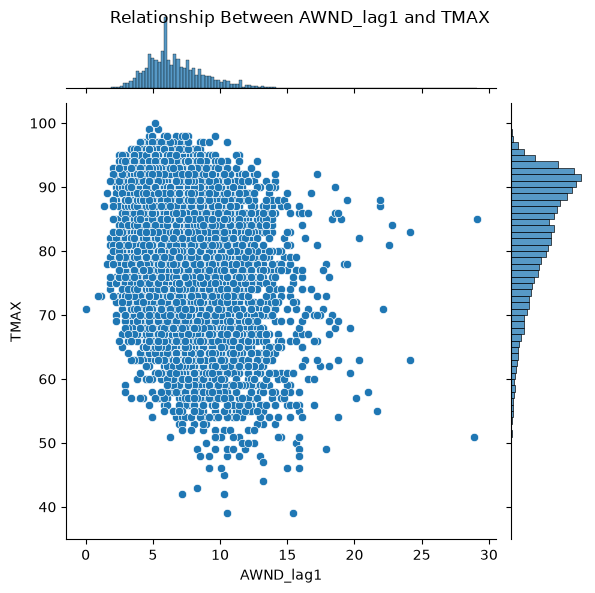

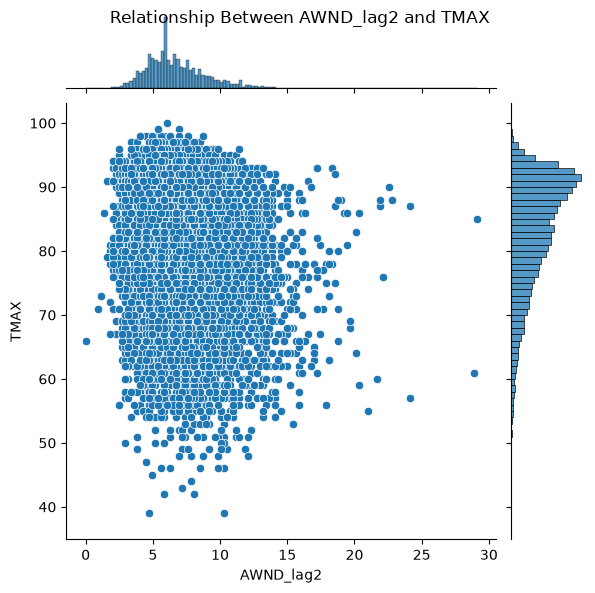

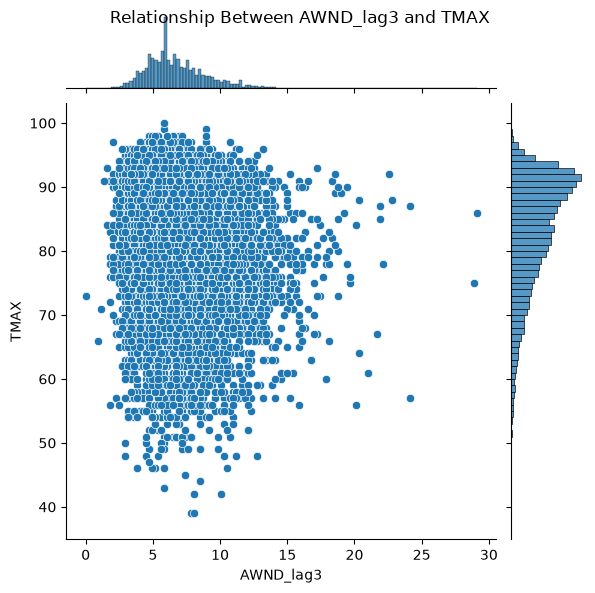

In [57]:
g = sns.jointplot(data=ghcnd_df, x="AWND_lag1", y="TMAX")
g.fig.suptitle("Relationship Between AWND_lag1 and TMAX")

g = sns.jointplot(data=ghcnd_df, x="AWND_lag2", y="TMAX")
g.fig.suptitle("Relationship Between AWND_lag2 and TMAX")

g = sns.jointplot(data=ghcnd_df, x="AWND_lag3", y="TMAX")
g.fig.suptitle("Relationship Between AWND_lag3 and TMAX")

plt.show()

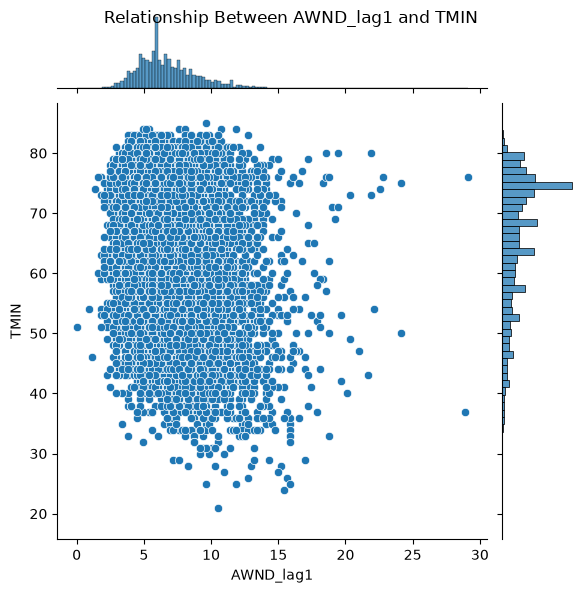

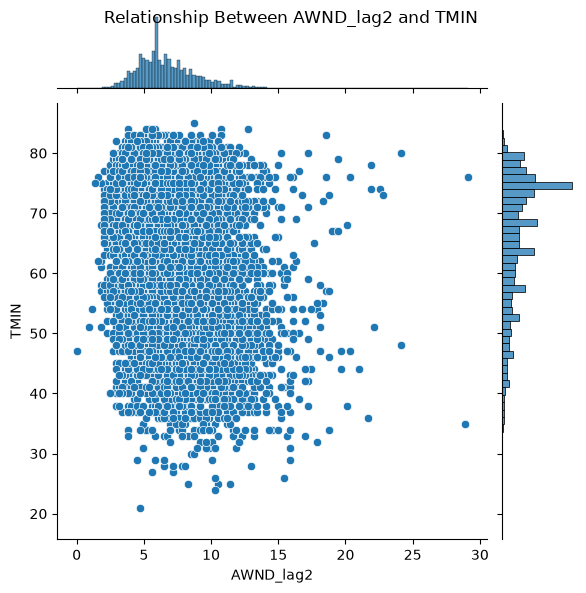

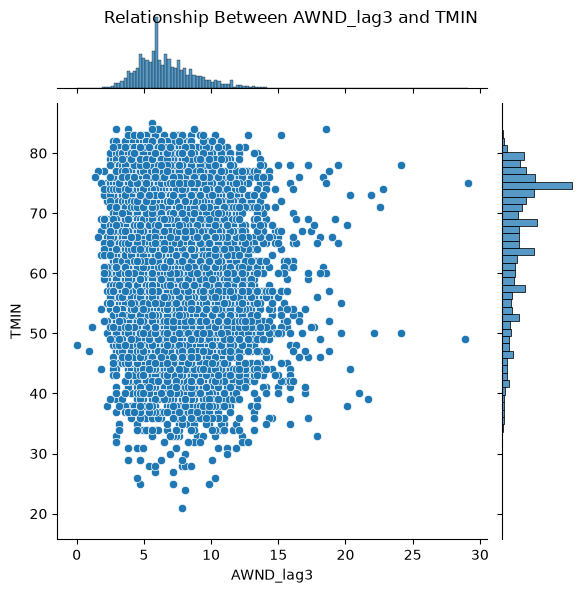

In [58]:
g = sns.jointplot(data=ghcnd_df, x="AWND_lag1", y="TMIN")
g.fig.suptitle("Relationship Between AWND_lag1 and TMIN")

g = sns.jointplot(data=ghcnd_df, x="AWND_lag2", y="TMIN")
g.fig.suptitle("Relationship Between AWND_lag2 and TMIN")

g = sns.jointplot(data=ghcnd_df, x="AWND_lag3", y="TMIN")
g.fig.suptitle("Relationship Between AWND_lag3 and TMIN")

plt.show()

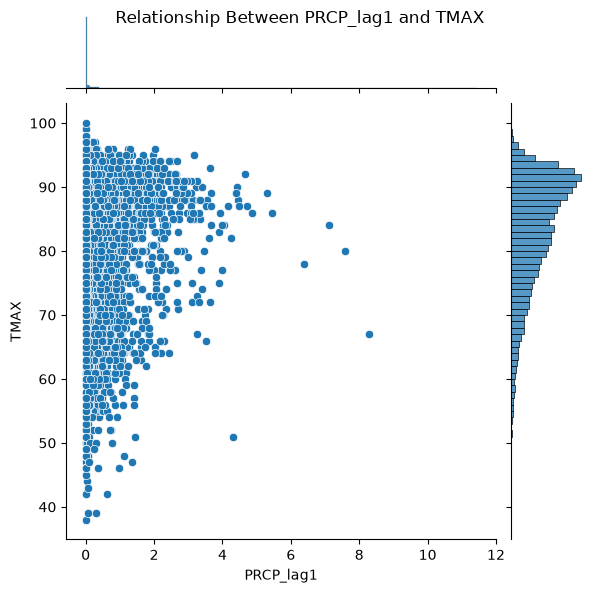

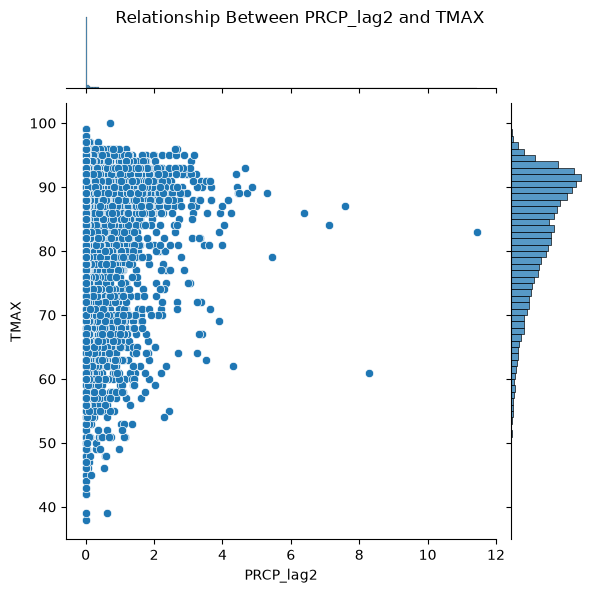

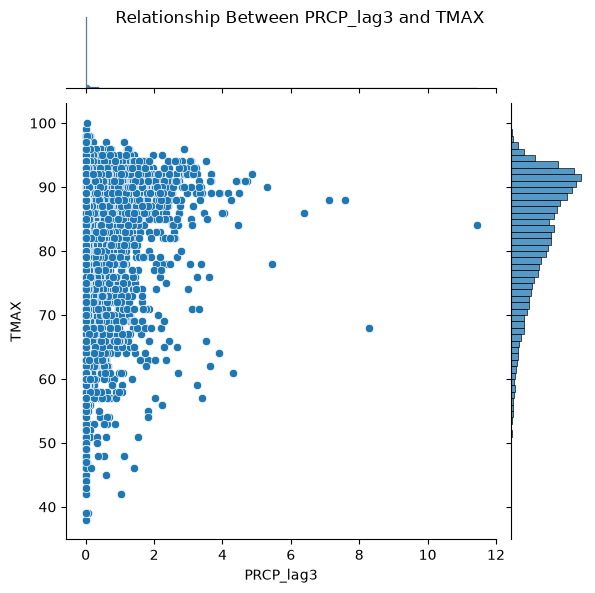

In [59]:
g = sns.jointplot(data=ghcnd_df, x="PRCP_lag1", y="TMAX")
g.fig.suptitle("Relationship Between PRCP_lag1 and TMAX")

g = sns.jointplot(data=ghcnd_df, x="PRCP_lag2", y="TMAX")
g.fig.suptitle("Relationship Between PRCP_lag2 and TMAX")

g = sns.jointplot(data=ghcnd_df, x="PRCP_lag3", y="TMAX")
g.fig.suptitle("Relationship Between PRCP_lag3 and TMAX")

plt.show()

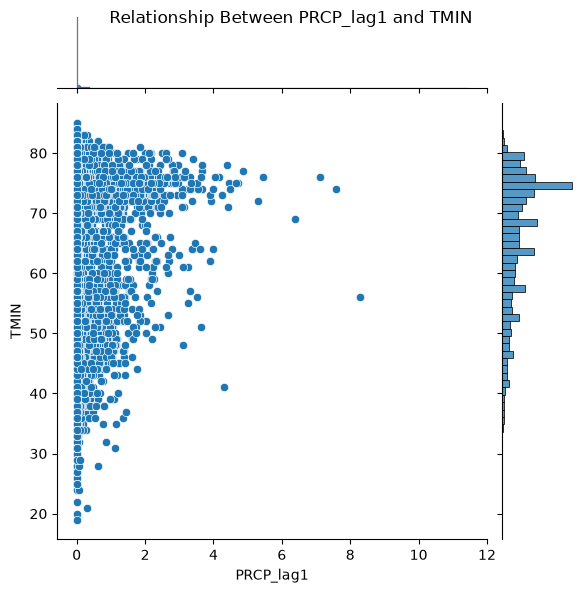

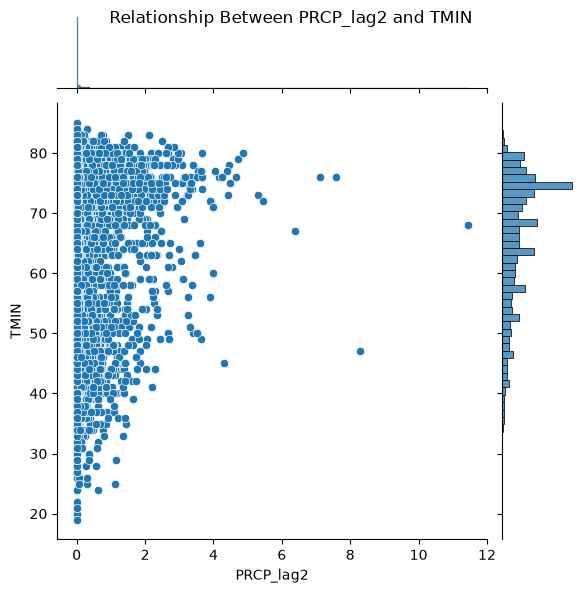

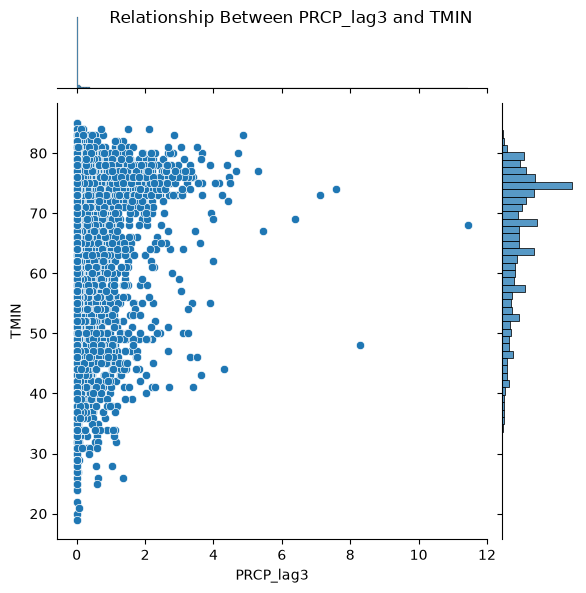

In [60]:
g = sns.jointplot(data=ghcnd_df, x="PRCP_lag1", y="TMIN")
g.fig.suptitle("Relationship Between PRCP_lag1 and TMIN")

g = sns.jointplot(data=ghcnd_df, x="PRCP_lag2", y="TMIN")
g.fig.suptitle("Relationship Between PRCP_lag2 and TMIN")

g = sns.jointplot(data=ghcnd_df, x="PRCP_lag3", y="TMIN")
g.fig.suptitle("Relationship Between PRCP_lag3 and TMIN")

plt.show()

#### Wind Direction & Max Wind Speeds Cols
- WDF1/WDFG to WDF2/WDF5: There's a transition at (10/31/1995)
- WSF1/WSFG to WSF2/WSF5: There's a transition at (10/31/1995)

In [61]:
ghcnd_df[TIME_COLS + WIND_COLS].head()

,DATE,WDF1,WDFG,WDF2,WDF5,WSF1,WSFG,WSF2,WSF5
0,1980-01-01,330.0,315.0,NaN,NaN,16.1,21.9,NaN,NaN
1,1980-01-02,270.0,270.0,NaN,NaN,14.1,24.2,NaN,NaN
2,1980-01-03,120.0,135.0,NaN,NaN,10.1,15.0,NaN,NaN
3,1980-01-04,140.0,135.0,NaN,NaN,19.9,31.1,NaN,NaN
4,1980-01-05,330.0,315.0,NaN,NaN,17.0,24.2,NaN,NaN


In [62]:
ghcnd_df[TIME_COLS + WIND_COLS].info()

<class 'pandas.DataFrame'>
RangeIndex: 17093 entries, 0 to 17092
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   DATE    17093 non-null  datetime64[us]
 1   WDF1    5783 non-null   float64       
 2   WDFG    5675 non-null   float64       
 3   WDF2    11304 non-null  float64       
 4   WDF5    11253 non-null  float64       
 5   WSF1    5783 non-null   float64       
 6   WSFG    5676 non-null   float64       
 7   WSF2    11304 non-null  float64       
 8   WSF5    11253 non-null  float64       
dtypes: datetime64[us](1), float64(8)
memory usage: 1.2 MB


In [63]:
ghcnd_df["WDFG_lag1"] = ghcnd_df["WDFG"].shift(1)
ghcnd_df["WDF1_lag1"] = ghcnd_df["WDF1"].shift(1)
ghcnd_df["WDF2_lag1"] = ghcnd_df["WDF2"].shift(1)
ghcnd_df["WDF5_lag1"] = ghcnd_df["WDF5"].shift(1)

ghcnd_df["WSFG_lag1"] = ghcnd_df["WSFG"].shift(1)
ghcnd_df["WSF1_lag1"] = ghcnd_df["WSF1"].shift(1)
ghcnd_df["WSF2_lag1"] = ghcnd_df["WSF2"].shift(1)
ghcnd_df["WSF5_lag1"] = ghcnd_df["WSF5"].shift(1)

ghcnd_df["WDFG_lag2"] = ghcnd_df["WDFG"].shift(2)
ghcnd_df["WDF1_lag2"] = ghcnd_df["WDF1"].shift(2)
ghcnd_df["WDF2_lag2"] = ghcnd_df["WDF2"].shift(2)
ghcnd_df["WDF5_lag2"] = ghcnd_df["WDF5"].shift(2)

ghcnd_df["WSFG_lag2"] = ghcnd_df["WSFG"].shift(2)
ghcnd_df["WSF1_lag2"] = ghcnd_df["WSF1"].shift(2)
ghcnd_df["WSF2_lag2"] = ghcnd_df["WSF2"].shift(2)
ghcnd_df["WSF5_lag2"] = ghcnd_df["WSF5"].shift(2)

ghcnd_df["WDFG_lag3"] = ghcnd_df["WDFG"].shift(3)
ghcnd_df["WDF1_lag3"] = ghcnd_df["WDF1"].shift(3)
ghcnd_df["WDF2_lag3"] = ghcnd_df["WDF2"].shift(3)
ghcnd_df["WDF5_lag3"] = ghcnd_df["WDF5"].shift(3)

ghcnd_df["WSFG_lag3"] = ghcnd_df["WSFG"].shift(3)
ghcnd_df["WSF1_lag3"] = ghcnd_df["WSF1"].shift(3)
ghcnd_df["WSF2_lag3"] = ghcnd_df["WSF2"].shift(3)
ghcnd_df["WSF5_lag3"] = ghcnd_df["WSF5"].shift(3)


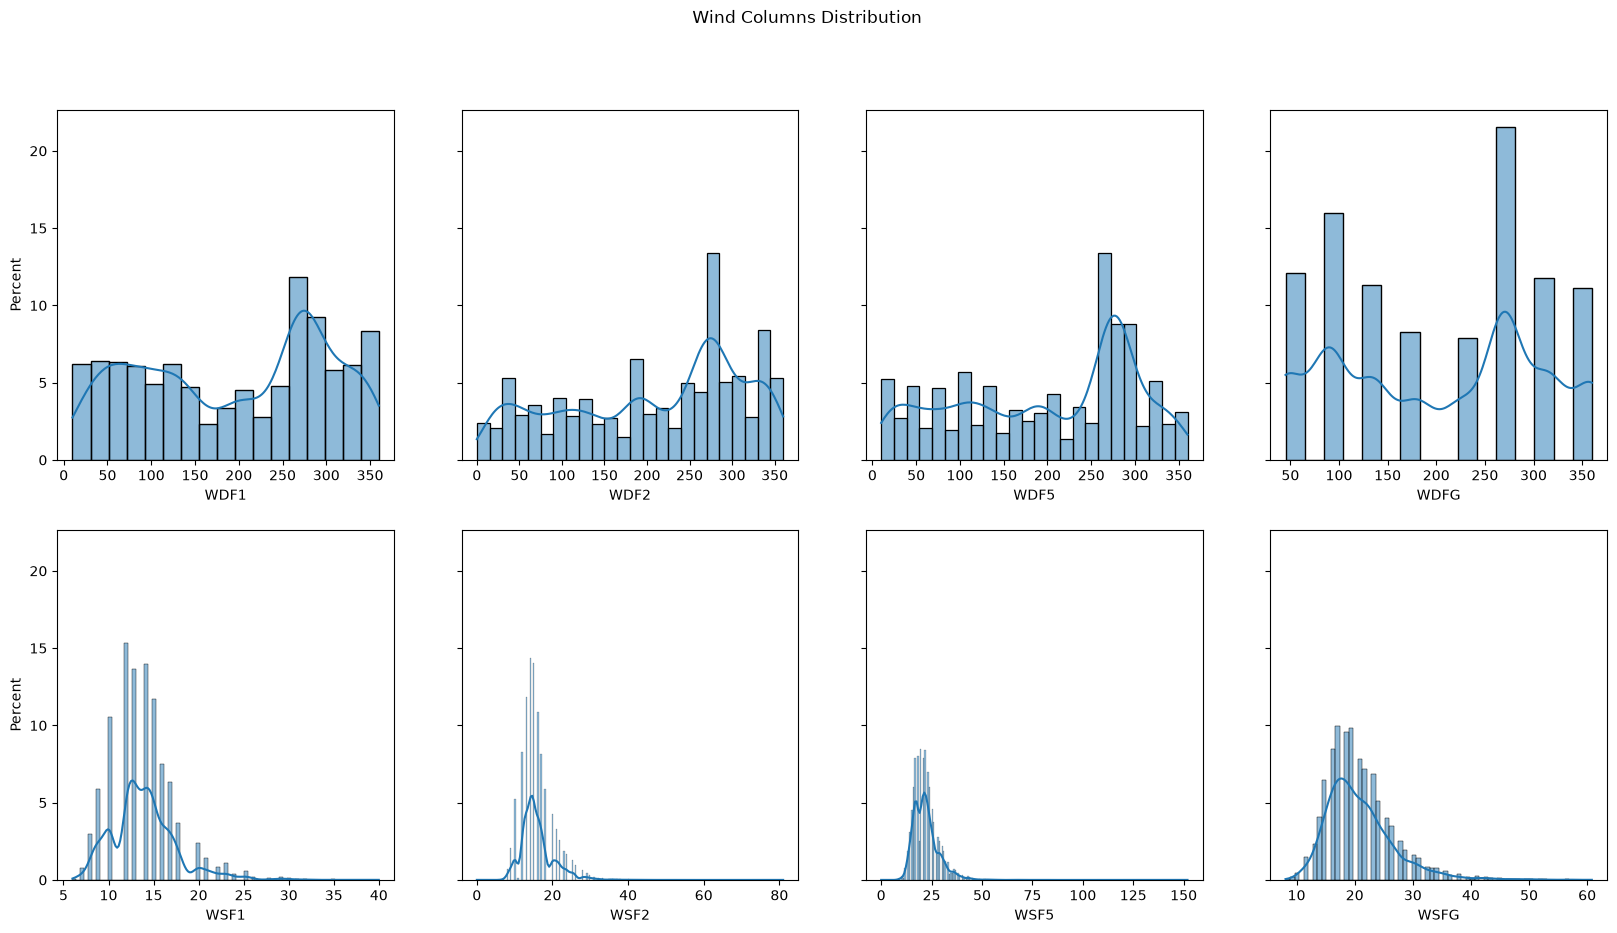

In [64]:
fig, axs = plt.subplots(2, 4, figsize=(20, 10), sharey=True)

sns.histplot(data=ghcnd_df, x="WDFG", kde=True, stat="percent", ax=axs[0][3])
sns.histplot(data=ghcnd_df, x="WDF1", kde=True, stat="percent", ax=axs[0][0])
sns.histplot(data=ghcnd_df, x="WDF2", kde=True, stat="percent", ax=axs[0][1])
sns.histplot(data=ghcnd_df, x="WDF5", kde=True, stat="percent", ax=axs[0][2])

sns.histplot(data=ghcnd_df, x="WSFG", kde=True, stat="percent", ax=axs[1][3])
sns.histplot(data=ghcnd_df, x="WSF1", kde=True, stat="percent", ax=axs[1][0])
sns.histplot(data=ghcnd_df, x="WSF2", kde=True, stat="percent", ax=axs[1][1])
sns.histplot(data=ghcnd_df, x="WSF5", kde=True, stat="percent", ax=axs[1][2])

fig.suptitle("Wind Columns Distribution")

plt.show()

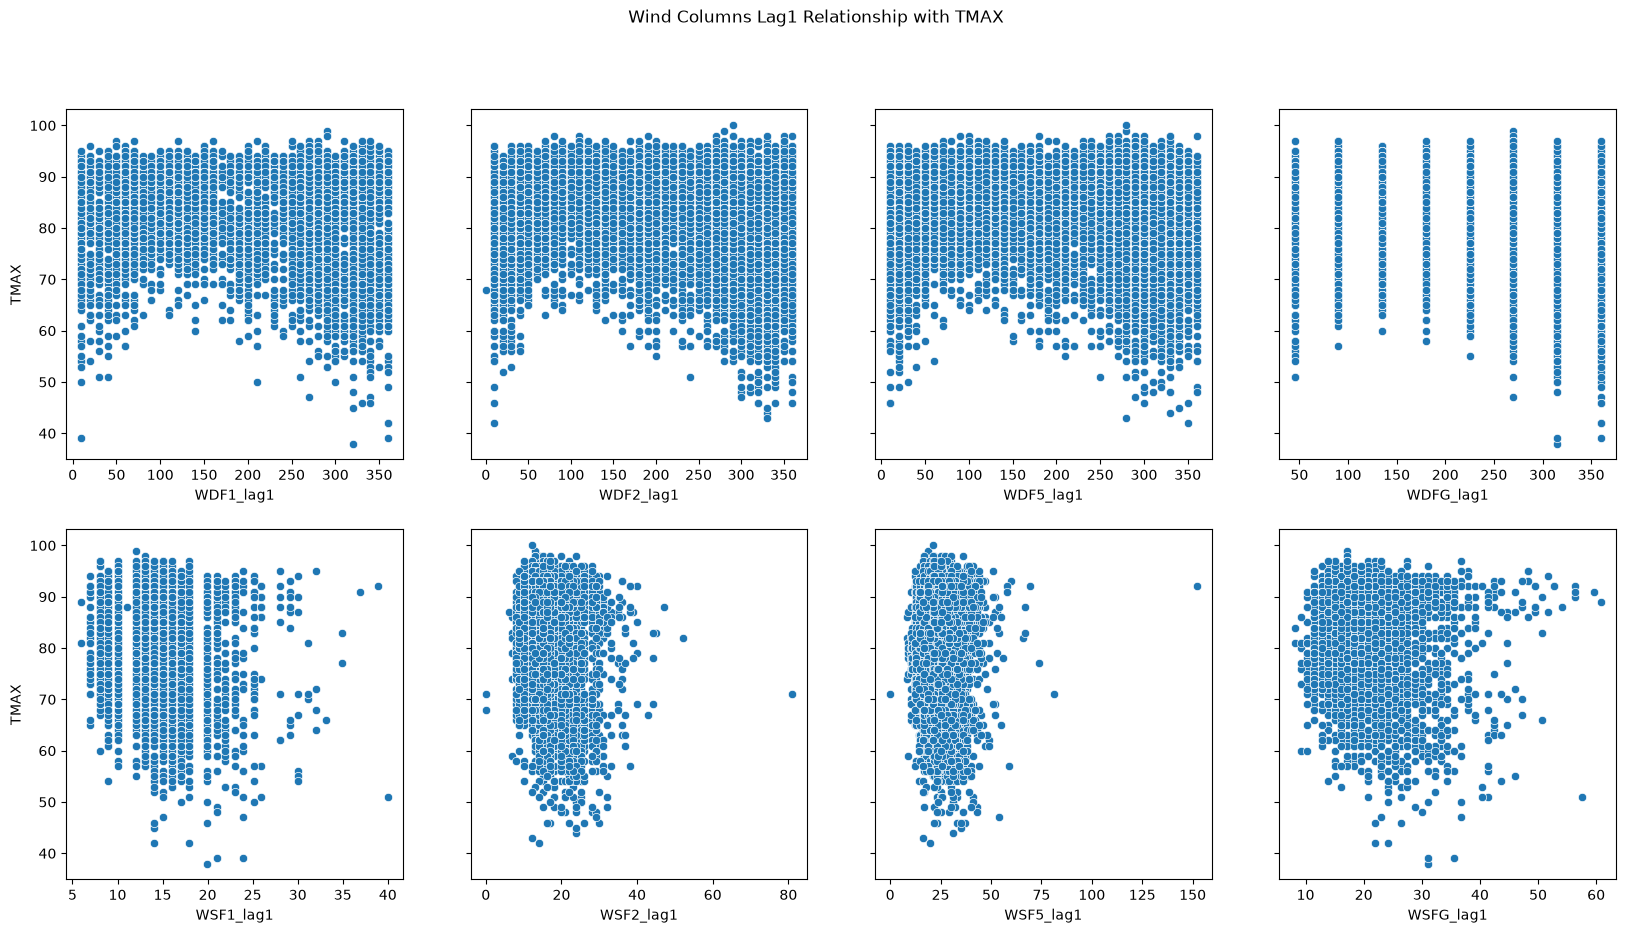

In [65]:
fig, axs = plt.subplots(2, 4, figsize=(20, 10), sharey=True)

sns.scatterplot(data=ghcnd_df, x="WDFG_lag1", y="TMAX", ax=axs[0][3])
sns.scatterplot(data=ghcnd_df, x="WDF1_lag1", y="TMAX", ax=axs[0][0])
sns.scatterplot(data=ghcnd_df, x="WDF2_lag1", y="TMAX", ax=axs[0][1])
sns.scatterplot(data=ghcnd_df, x="WDF5_lag1", y="TMAX", ax=axs[0][2])

sns.scatterplot(data=ghcnd_df, x="WSFG_lag1", y="TMAX", ax=axs[1][3])
sns.scatterplot(data=ghcnd_df, x="WSF1_lag1", y="TMAX", ax=axs[1][0])
sns.scatterplot(data=ghcnd_df, x="WSF2_lag1", y="TMAX", ax=axs[1][1])
sns.scatterplot(data=ghcnd_df, x="WSF5_lag1", y="TMAX", ax=axs[1][2])

fig.suptitle("Wind Columns Lag1 Relationship with TMAX")

plt.show()

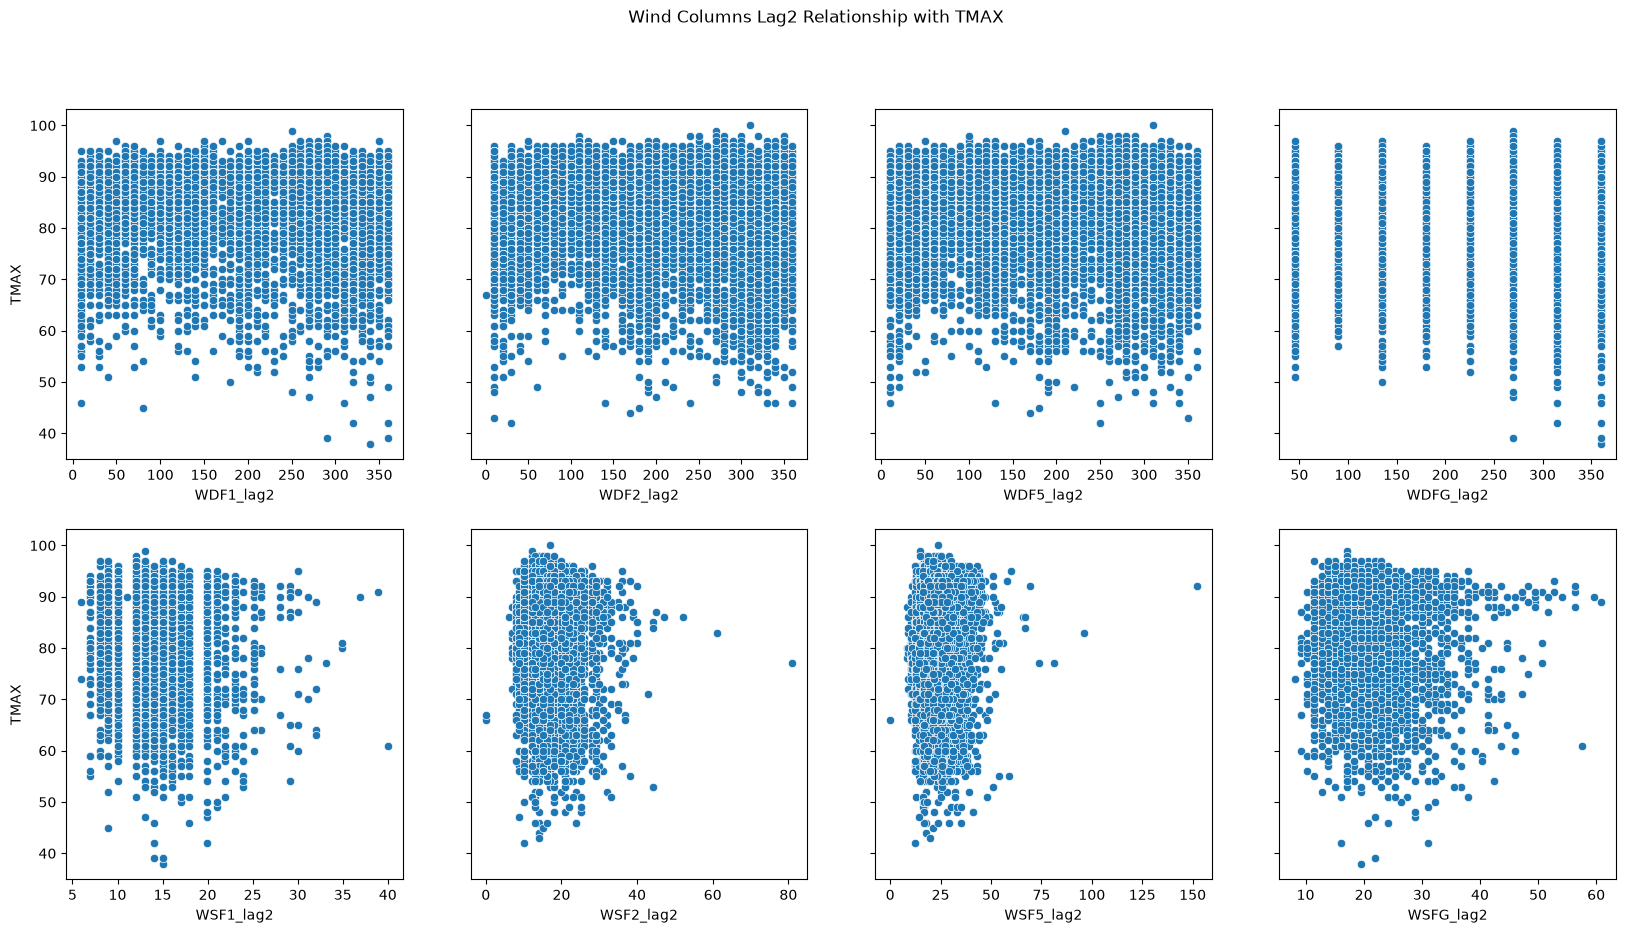

In [66]:
fig, axs = plt.subplots(2, 4, figsize=(20, 10), sharey=True)

sns.scatterplot(data=ghcnd_df, x="WDFG_lag2", y="TMAX", ax=axs[0][3])
sns.scatterplot(data=ghcnd_df, x="WDF1_lag2", y="TMAX", ax=axs[0][0])
sns.scatterplot(data=ghcnd_df, x="WDF2_lag2", y="TMAX", ax=axs[0][1])
sns.scatterplot(data=ghcnd_df, x="WDF5_lag2", y="TMAX", ax=axs[0][2])

sns.scatterplot(data=ghcnd_df, x="WSFG_lag2", y="TMAX", ax=axs[1][3])
sns.scatterplot(data=ghcnd_df, x="WSF1_lag2", y="TMAX", ax=axs[1][0])
sns.scatterplot(data=ghcnd_df, x="WSF2_lag2", y="TMAX", ax=axs[1][1])
sns.scatterplot(data=ghcnd_df, x="WSF5_lag2", y="TMAX", ax=axs[1][2])

fig.suptitle("Wind Columns Lag2 Relationship with TMAX")

plt.show()

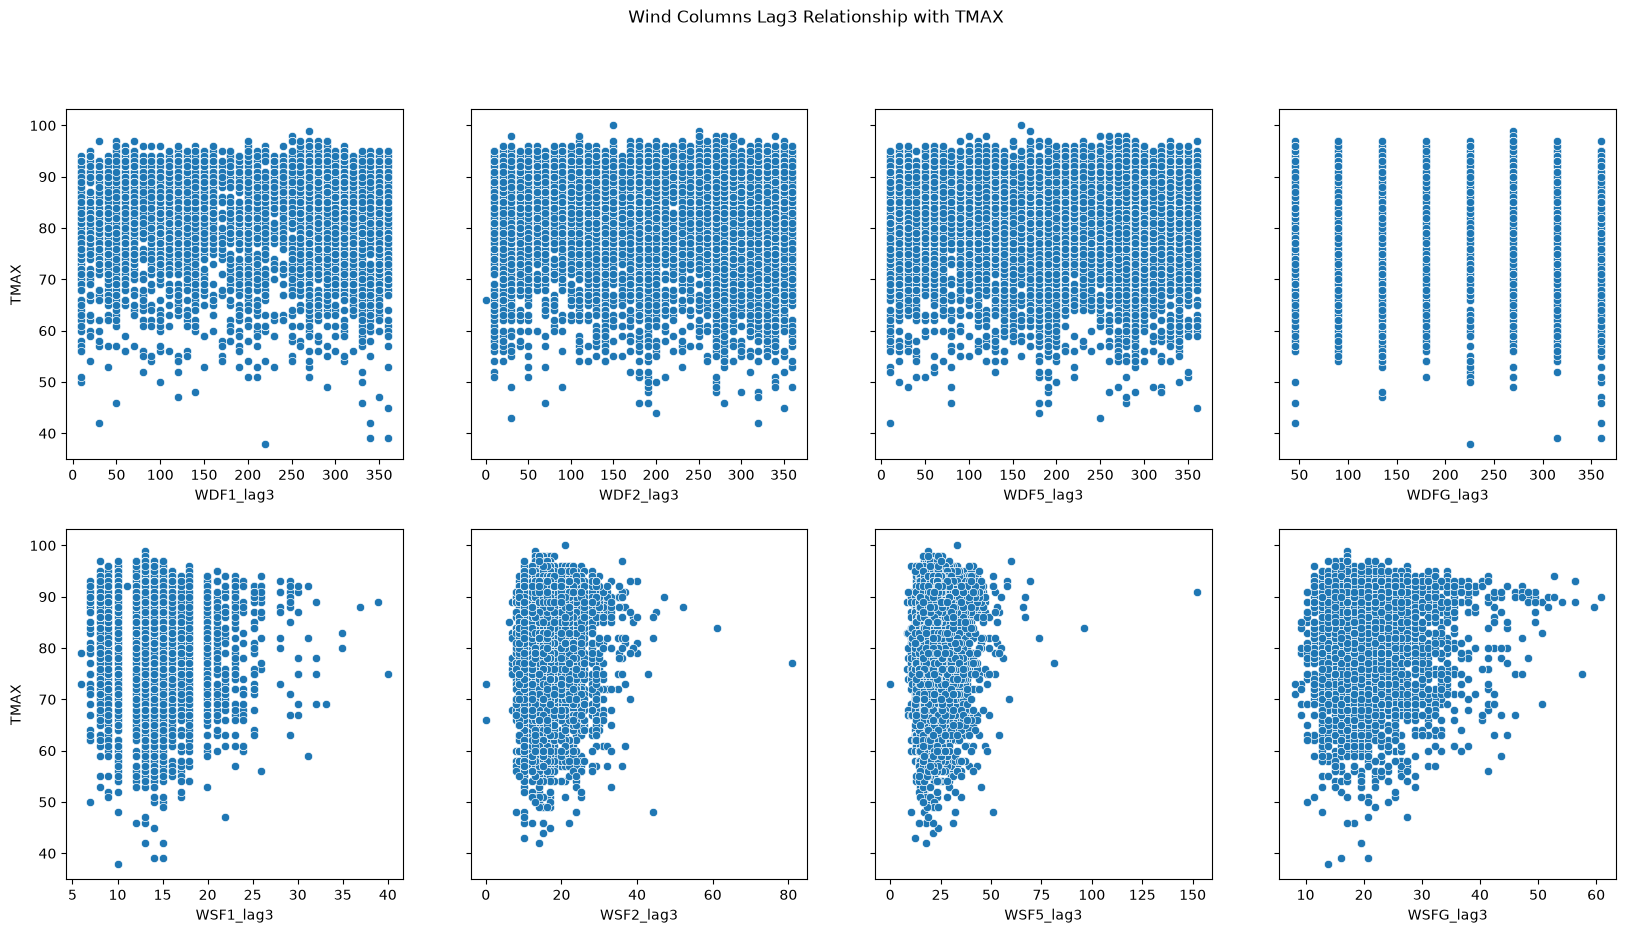

In [67]:
fig, axs = plt.subplots(2, 4, figsize=(20, 10), sharey=True)

sns.scatterplot(data=ghcnd_df, x="WDFG_lag3", y="TMAX", ax=axs[0][3])
sns.scatterplot(data=ghcnd_df, x="WDF1_lag3", y="TMAX", ax=axs[0][0])
sns.scatterplot(data=ghcnd_df, x="WDF2_lag3", y="TMAX", ax=axs[0][1])
sns.scatterplot(data=ghcnd_df, x="WDF5_lag3", y="TMAX", ax=axs[0][2])

sns.scatterplot(data=ghcnd_df, x="WSFG_lag3", y="TMAX", ax=axs[1][3])
sns.scatterplot(data=ghcnd_df, x="WSF1_lag3", y="TMAX", ax=axs[1][0])
sns.scatterplot(data=ghcnd_df, x="WSF2_lag3", y="TMAX", ax=axs[1][1])
sns.scatterplot(data=ghcnd_df, x="WSF5_lag3", y="TMAX", ax=axs[1][2])

fig.suptitle("Wind Columns Lag3 Relationship with TMAX")

plt.show()

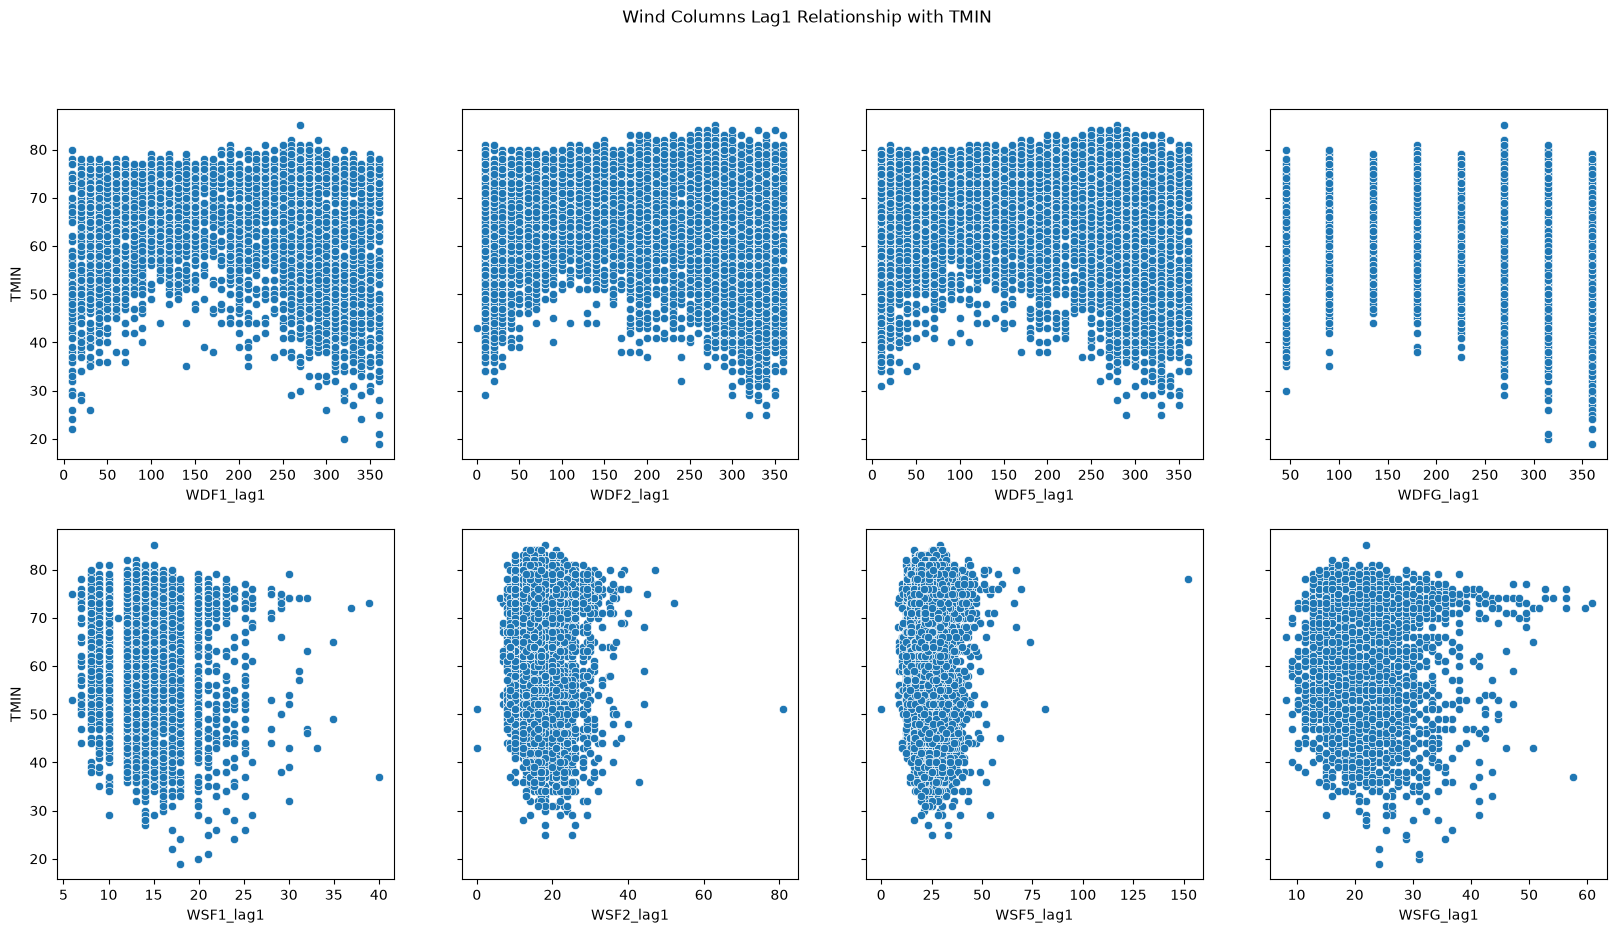

In [68]:
fig, axs = plt.subplots(2, 4, figsize=(20, 10), sharey=True)

sns.scatterplot(data=ghcnd_df, x="WDFG_lag1", y="TMIN", ax=axs[0][3])
sns.scatterplot(data=ghcnd_df, x="WDF1_lag1", y="TMIN", ax=axs[0][0])
sns.scatterplot(data=ghcnd_df, x="WDF2_lag1", y="TMIN", ax=axs[0][1])
sns.scatterplot(data=ghcnd_df, x="WDF5_lag1", y="TMIN", ax=axs[0][2])

sns.scatterplot(data=ghcnd_df, x="WSFG_lag1", y="TMIN", ax=axs[1][3])
sns.scatterplot(data=ghcnd_df, x="WSF1_lag1", y="TMIN", ax=axs[1][0])
sns.scatterplot(data=ghcnd_df, x="WSF2_lag1", y="TMIN", ax=axs[1][1])
sns.scatterplot(data=ghcnd_df, x="WSF5_lag1", y="TMIN", ax=axs[1][2])

fig.suptitle("Wind Columns Lag1 Relationship with TMIN")

plt.show()

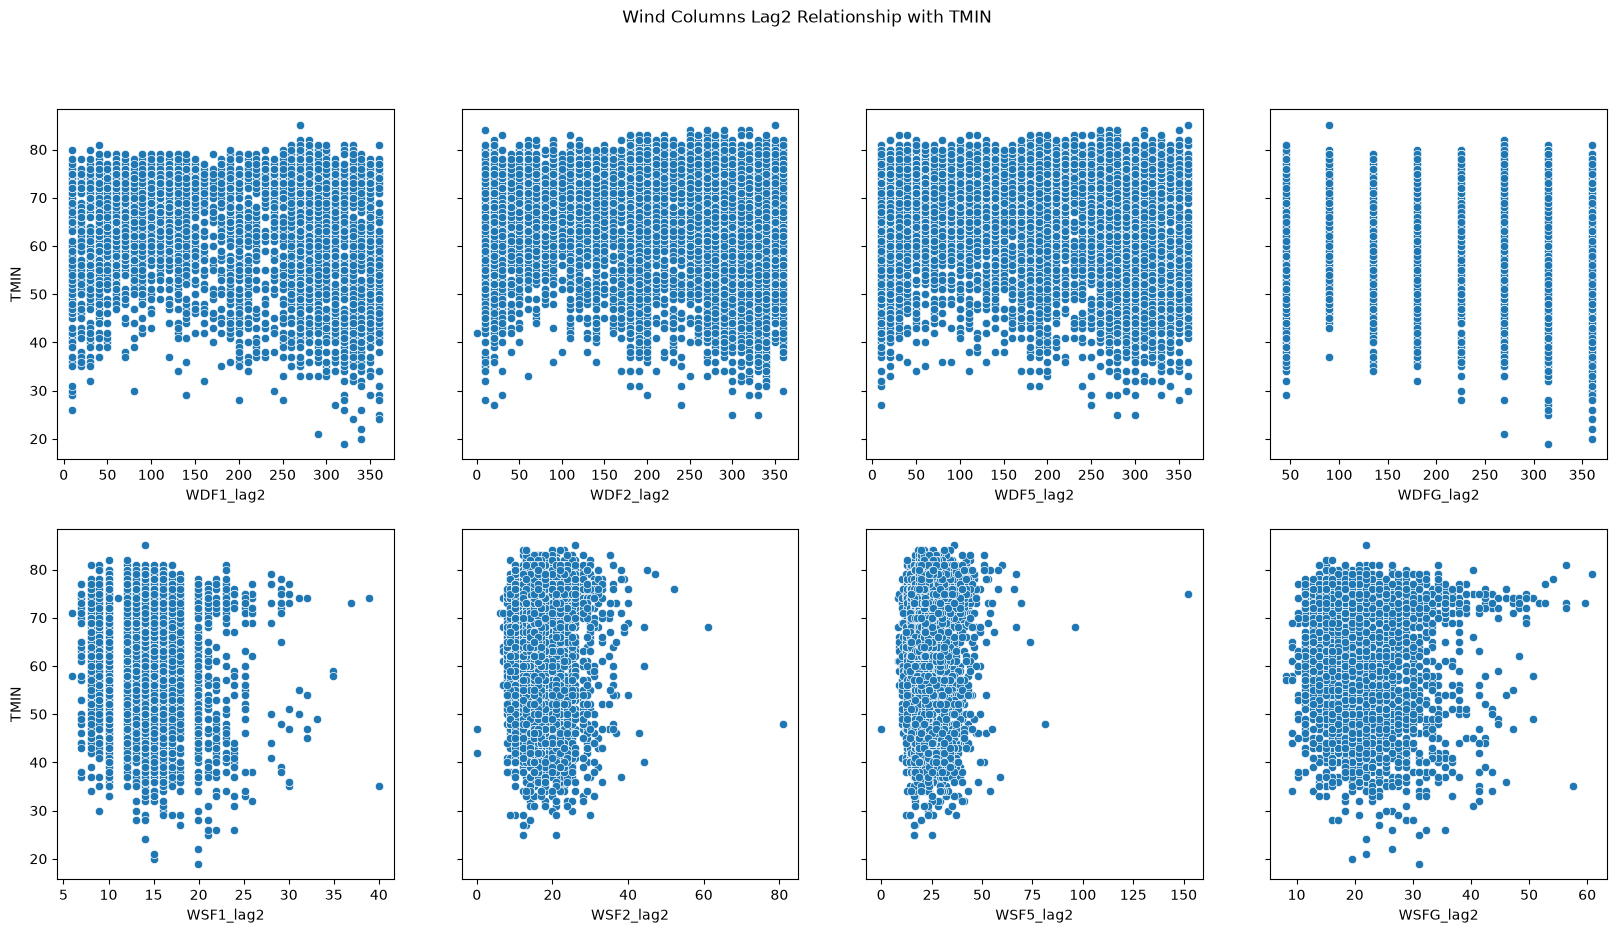

In [69]:
fig, axs = plt.subplots(2, 4, figsize=(20, 10), sharey=True)

sns.scatterplot(data=ghcnd_df, x="WDFG_lag2", y="TMIN", ax=axs[0][3])
sns.scatterplot(data=ghcnd_df, x="WDF1_lag2", y="TMIN", ax=axs[0][0])
sns.scatterplot(data=ghcnd_df, x="WDF2_lag2", y="TMIN", ax=axs[0][1])
sns.scatterplot(data=ghcnd_df, x="WDF5_lag2", y="TMIN", ax=axs[0][2])

sns.scatterplot(data=ghcnd_df, x="WSFG_lag2", y="TMIN", ax=axs[1][3])
sns.scatterplot(data=ghcnd_df, x="WSF1_lag2", y="TMIN", ax=axs[1][0])
sns.scatterplot(data=ghcnd_df, x="WSF2_lag2", y="TMIN", ax=axs[1][1])
sns.scatterplot(data=ghcnd_df, x="WSF5_lag2", y="TMIN", ax=axs[1][2])

fig.suptitle("Wind Columns Lag2 Relationship with TMIN")

plt.show()

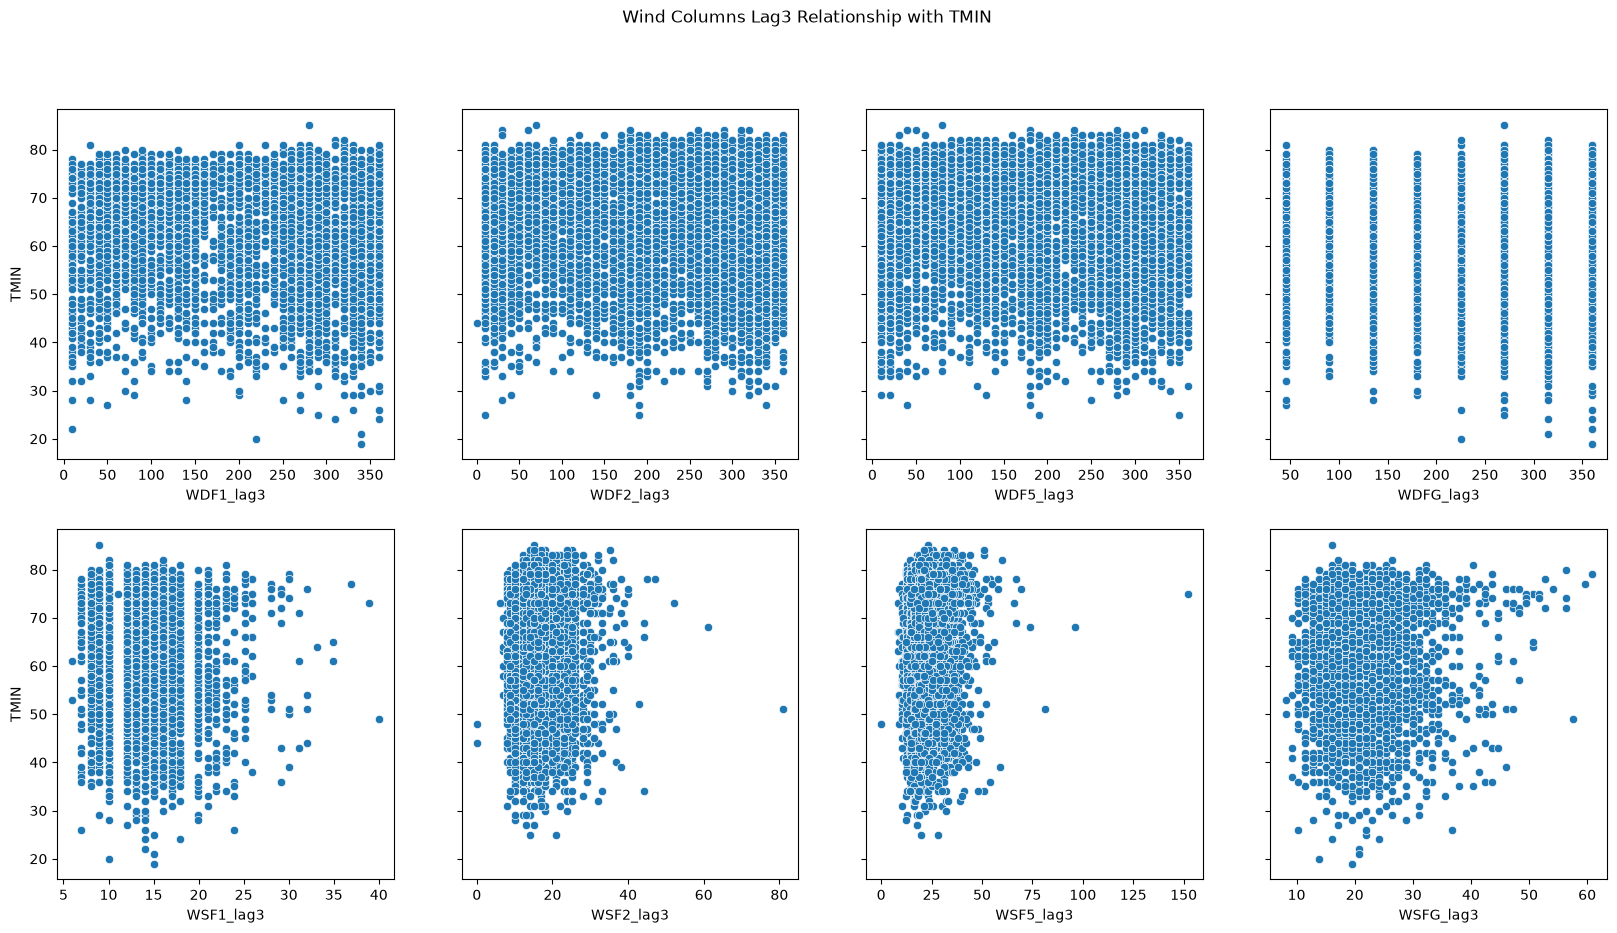

In [70]:
fig, axs = plt.subplots(2, 4, figsize=(20, 10), sharey=True)

sns.scatterplot(data=ghcnd_df, x="WDFG_lag3", y="TMIN", ax=axs[0][3])
sns.scatterplot(data=ghcnd_df, x="WDF1_lag3", y="TMIN", ax=axs[0][0])
sns.scatterplot(data=ghcnd_df, x="WDF2_lag3", y="TMIN", ax=axs[0][1])
sns.scatterplot(data=ghcnd_df, x="WDF5_lag3", y="TMIN", ax=axs[0][2])

sns.scatterplot(data=ghcnd_df, x="WSFG_lag3", y="TMIN", ax=axs[1][3])
sns.scatterplot(data=ghcnd_df, x="WSF1_lag3", y="TMIN", ax=axs[1][0])
sns.scatterplot(data=ghcnd_df, x="WSF2_lag3", y="TMIN", ax=axs[1][1])
sns.scatterplot(data=ghcnd_df, x="WSF5_lag3", y="TMIN", ax=axs[1][2])

fig.suptitle("Wind Columns Lag3 Relationship with TMIN")

plt.show()

#### Weather Types
Event Types:
- WT01: Fog, ice fog, or freezing fog (may include heavy fog)
- WT02: Heavy fog or heaving freezing fog (not always distinguished from fog)
- WT03: Thunder
- WT04: Ice pellets, sleet, snow pellets, or small hail 
- WT05: Hail
- WT06: Glaze
- WT07: Dust
- WT08: Smoke or haze
- WT09: Blowing or drifting snow
- WT10: Tornado, waterspout, or funnel cloud
- WT11: High or damaging winds
- WT13: Mist
- WT14: Drizzle
- WT15: Freezing Drizzle
- WT16: Rain
- WT18: Snow, snow pellets, snow grains, or ice crystals
- WT21: Ground fog
- WV03: Thunder

WT01-3 & WT08 appear constantly throughout the data, so I will analyze the data. But, I might have to drop the data as it might not be easy to collect in production.
- The events tend to correspond with higher temperatures.

In [71]:
ghcnd_df[TIME_COLS + WEATHER_TYPE_COLS].head()

,DATE,WT01,WT02,WT03,WT04,WT05,WT06,WT07,WT08,WT09,WT10,WT11,WT13,WT14,WT15,WT16,WT18,WT21,WV03
0,1980-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
1,1980-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1980-01-03,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1980-01-04,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
4,1980-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [72]:
ghcnd_df[TIME_COLS + WEATHER_TYPE_COLS].info()

<class 'pandas.DataFrame'>
RangeIndex: 17093 entries, 0 to 17092
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   DATE    17093 non-null  datetime64[us]
 1   WT01    6117 non-null   float64       
 2   WT02    543 non-null    float64       
 3   WT03    3684 non-null   float64       
 4   WT04    3 non-null      float64       
 5   WT05    295 non-null    float64       
 6   WT06    1 non-null      float64       
 7   WT07    69 non-null     float64       
 8   WT08    3378 non-null   float64       
 9   WT09    14 non-null     float64       
 10  WT10    42 non-null     float64       
 11  WT11    4 non-null      float64       
 12  WT13    2131 non-null   float64       
 13  WT14    176 non-null    float64       
 14  WT15    1 non-null      float64       
 15  WT16    4590 non-null   float64       
 16  WT18    4 non-null      float64       
 17  WT21    38 non-null     float64       
 18  WV03    1 non-nul

In [73]:
ghcnd_df.groupby(by="YEAR")[WEATHER_TYPE_COLS].count()

,WT01,WT02,WT03,WT04,WT05,WT06,WT07,WT08,WT09,WT10,WT11,WT13,WT14,WT15,WT16,WT18,WT21,WV03
YEAR,,,,,,,,,,,,,,,,,,
1980,179,19,77,0,2,0,0,83,0,0,0,0,0,0,153,1,0,0
1981,165,16,79,0,0,0,0,108,0,0,0,0,0,0,127,0,0,0
1982,146,16,86,0,1,0,0,71,0,0,0,0,0,0,142,0,0,0
1983,144,21,88,0,1,0,0,62,0,0,0,0,0,0,164,0,0,0
1984,148,18,78,0,1,0,0,91,0,2,0,0,11,0,137,1,0,0
1985,115,9,89,0,0,0,0,58,0,4,0,0,2,0,149,0,0,0
1986,121,20,91,0,0,0,0,55,0,1,0,0,8,0,157,0,0,0
1987,151,14,78,0,0,0,0,71,0,4,0,0,11,0,145,0,0,0
1988,175,11,65,0,0,0,0,91,0,0,0,0,17,0,133,0,0,0


In [74]:
ghcnd_df.groupby(by="MONTH")[WEATHER_TYPE_COLS].count()

,WT01,WT02,WT03,WT04,WT05,WT06,WT07,WT08,WT09,WT10,WT11,WT13,WT14,WT15,WT16,WT18,WT21,WV03
MONTH,,,,,,,,,,,,,,,,,,
1,645,125,48,1,14,0,8,240,1,0,1,232,44,0,317,0,6,0
2,599,106,69,0,9,0,2,259,2,0,0,221,23,0,308,0,16,0
3,516,46,107,0,23,0,11,285,1,0,0,190,17,0,302,1,4,0
4,388,18,127,0,15,0,8,262,1,3,0,114,4,0,224,0,0,0
5,393,7,207,0,27,0,5,343,0,2,0,114,1,0,250,0,0,0
6,516,18,652,0,33,0,7,338,0,7,1,159,3,0,531,0,0,1
7,525,20,900,2,51,0,5,355,1,16,1,194,6,0,647,0,0,0
8,529,21,867,0,46,0,5,327,0,5,0,183,0,0,674,1,0,0
9,495,6,496,0,27,0,3,286,0,6,0,175,4,0,521,1,0,0


In [75]:
no_major_events_df = ghcnd_df[(ghcnd_df.WT01.isnull()) & (ghcnd_df.WT02.isnull()) & (ghcnd_df.WT03.isnull()) & (ghcnd_df.WT08.isnull())][TIME_COLS + TARGET_COLS]
wt01_days_df = ghcnd_df[(ghcnd_df.WT01.isnull())][TIME_COLS + TARGET_COLS]
wt02_days_df = ghcnd_df[(ghcnd_df.WT02.isnull())][TIME_COLS + TARGET_COLS]
wt03_days_df = ghcnd_df[(ghcnd_df.WT03.isnull())][TIME_COLS + TARGET_COLS]
wt08_days_df = ghcnd_df[(ghcnd_df.WT08.isnull())][TIME_COLS + TARGET_COLS]

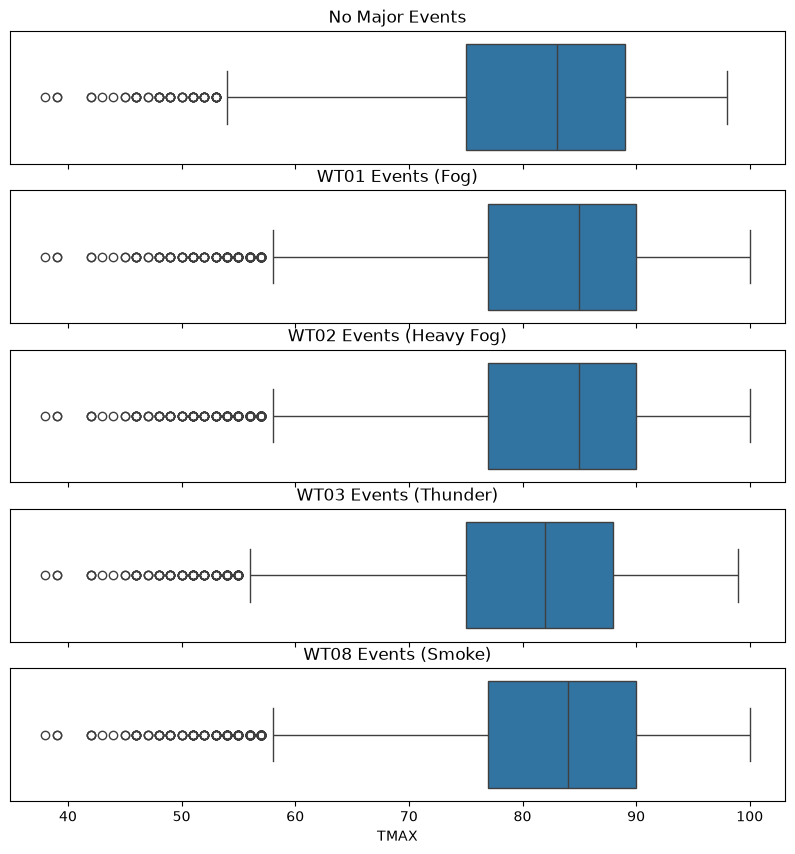

In [76]:
fig, axs = plt.subplots(nrows=5, ncols=1, figsize=(10, 10), sharex=True)

sns.boxplot(data=no_major_events_df, x="TMAX", ax=axs[0])
axs[0].set_title("No Major Events")
axs[0].set_yticks([])

sns.boxplot(data=wt01_days_df, x="TMAX", ax=axs[1])
axs[1].set_title("WT01 Events (Fog)")
axs[1].set_yticks([])

sns.boxplot(data=wt02_days_df, x="TMAX", ax=axs[2])
axs[2].set_title("WT02 Events (Heavy Fog)")
axs[2].set_yticks([])

sns.boxplot(data=wt03_days_df, x="TMAX", ax=axs[3])
axs[3].set_title("WT03 Events (Thunder)")
axs[3].set_yticks([])

sns.boxplot(data=wt08_days_df, x="TMAX", ax=axs[4])
axs[4].set_title("WT08 Events (Smoke)")
axs[4].set_yticks([])

plt.show()

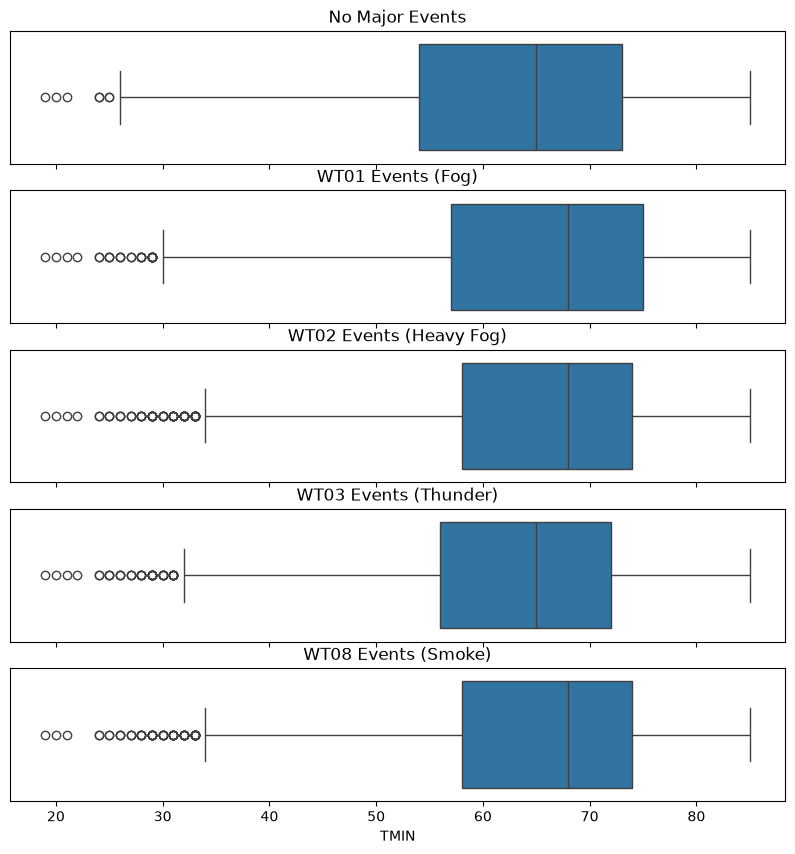

In [77]:
fig, axs = plt.subplots(nrows=5, ncols=1, figsize=(10, 10), sharex=True)

sns.boxplot(data=no_major_events_df, x="TMIN", ax=axs[0])
axs[0].set_title("No Major Events")
axs[0].set_yticks([])

sns.boxplot(data=wt01_days_df, x="TMIN", ax=axs[1])
axs[1].set_title("WT01 Events (Fog)")
axs[1].set_yticks([])

sns.boxplot(data=wt02_days_df, x="TMIN", ax=axs[2])
axs[2].set_title("WT02 Events (Heavy Fog)")
axs[2].set_yticks([])

sns.boxplot(data=wt03_days_df, x="TMIN", ax=axs[3])
axs[3].set_title("WT03 Events (Thunder)")
axs[3].set_yticks([])

sns.boxplot(data=wt08_days_df, x="TMIN", ax=axs[4])
axs[4].set_title("WT08 Events (Smoke)")
axs[4].set_yticks([])

plt.show()

### NOAA Weather.gov API Analysis
- To get values close to GHCND, you need to aggregate temperature to get mins and max for covered days.
- Also, take into account that the oldest day may be clipped, so use last ~6 days for honest coverage

In [78]:
# Targets, temperature, windDirection, windSpeed, windGust, precipitationLastHour, precipitationLast3Hours, precipitationLast6Hours
weather_gov_response = requests.get(r'https://api.weather.gov/stations/KTPA/observations?start=2026-10-01T00%3A00%3A00-04%3A00&end=2026-10-28T23%3A59%3A59-04%3A00&limit=200')
response_data = weather_gov_response.json()

all_weather_gov_data = []
while (weather_gov_response.status_code == 200 and len(response_data['features']) > 0):
    
    for data in response_data['features']:
        id_data = data['id']
        station_name_data = data['properties']['stationName']
        station_id_data = data['properties']['stationId']
        timestamp_data = data['properties']['timestamp']
        temperature_data = data['properties']['temperature']['value']*9/5 + 32 if data['properties']['temperature']['value'] is not None else None
        wind_direction_data = data['properties']['windDirection']['value']
        wind_speed_data = data['properties']['windSpeed']['value']/1.609 if data['properties']['windSpeed']['value'] is not None else None
        wind_gust_direction_data = data['properties']['windGust']['value']/1.609 if data['properties']['windGust']['value'] is not None else None
        precipitation_last_3hours = data['properties']['precipitationLast3Hours']['value']/25.4 if data['properties']['precipitationLast3Hours']['value'] is not None else 0

        all_weather_gov_data.append(
            {
                'id': id_data,
                'station_name': station_name_data,
                'station_id': station_id_data,
                'timestamp': timestamp_data,
                'temperature_farenheit': temperature_data,
                'wind_direction_degrees': wind_direction_data,
                'wind_speed_mi_h-1': wind_speed_data,
                'wind_gust_mi_h-1': wind_gust_direction_data,
                'precipitation_last_3hours_in': precipitation_last_3hours
            }
        )

    weather_gov_response = requests.get(response_data['pagination']['next'])
    response_data = weather_gov_response.json()

In [79]:
weather_gov_df = pd.DataFrame(all_weather_gov_data)
weather_gov_df['timestamp'] = pd.to_datetime(weather_gov_df['timestamp']).dt.tz_convert('US/Eastern')
weather_gov_df.set_index("timestamp")

,id,station_name,station_id,temperature_farenheit,wind_direction_degrees,wind_speed_mi_h-1,wind_gust_mi_h-1,precipitation_last_3hours_in
timestamp,,,,,,,,
2026-10-28 23:55:00-04:00,https://api.weather.gov/stations/KTPA/observat...,"Tampa, Tampa International Airport",KTPA,73.40,30.0,9.218148,NaN,0
2026-10-28 23:53:00-04:00,https://api.weather.gov/stations/KTPA/observat...,"Tampa, Tampa International Airport",KTPA,73.94,30.0,9.173400,NaN,0
2026-10-28 22:53:00-04:00,https://api.weather.gov/stations/KTPA/observat...,"Tampa, Tampa International Airport",KTPA,75.02,40.0,8.054692,18.346799,0
2026-10-28 22:40:00-04:00,https://api.weather.gov/stations/KTPA/observat...,"Tampa, Tampa International Airport",KTPA,75.20,50.0,11.500311,18.413922,0
2026-10-28 22:30:00-04:00,https://api.weather.gov/stations/KTPA/observat...,"Tampa, Tampa International Airport",KTPA,75.20,30.0,9.218148,NaN,0
...,...,...,...,...,...,...,...,...
2026-10-22 20:50:00-04:00,https://api.weather.gov/stations/KTPA/observat...,"Tampa, Tampa International Airport",KTPA,69.80,360.0,6.913611,NaN,0
2026-10-22 20:45:00-04:00,https://api.weather.gov/stations/KTPA/observat...,"Tampa, Tampa International Airport",KTPA,69.80,350.0,5.750155,NaN,0
2026-10-22 20:25:00-04:00,https://api.weather.gov/stations/KTPA/observat...,"Tampa, Tampa International Airport",KTPA,71.60,10.0,4.609074,NaN,0


In [80]:
weather_gov_df['date'] = weather_gov_df['timestamp'].map(
    lambda x: x.strftime("%m/%d/%Y")
)

In [81]:
weather_gov_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype                     
---  ------                        --------------  -----                     
 0   id                            1096 non-null   str                       
 1   station_name                  1096 non-null   str                       
 2   station_id                    1096 non-null   str                       
 3   timestamp                     1096 non-null   datetime64[us, US/Eastern]
 4   temperature_farenheit         1095 non-null   float64                   
 5   wind_direction_degrees        977 non-null    float64                   
 6   wind_speed_mi_h-1             979 non-null    float64                   
 7   wind_gust_mi_h-1              383 non-null    float64                   
 8   precipitation_last_3hours_in  1096 non-null   int64                     
 9   date                          1096 non-nu

In [82]:
weather_gov_df.to_csv(r'../data/raw/weather_gov_data.csv')

In [83]:
weather_gov_df.head()

,id,station_name,station_id,timestamp,temperature_farenheit,wind_direction_degrees,wind_speed_mi_h-1,wind_gust_mi_h-1,precipitation_last_3hours_in,date
0,https://api.weather.gov/stations/KTPA/observat...,"Tampa, Tampa International Airport",KTPA,2026-10-28 23:55:00-04:00,73.40,30.0,9.218148,NaN,0,10/28/2026
1,https://api.weather.gov/stations/KTPA/observat...,"Tampa, Tampa International Airport",KTPA,2026-10-28 23:53:00-04:00,73.94,30.0,9.173400,NaN,0,10/28/2026
2,https://api.weather.gov/stations/KTPA/observat...,"Tampa, Tampa International Airport",KTPA,2026-10-28 22:53:00-04:00,75.02,40.0,8.054692,18.346799,0,10/28/2026
3,https://api.weather.gov/stations/KTPA/observat...,"Tampa, Tampa International Airport",KTPA,2026-10-28 22:40:00-04:00,75.20,50.0,11.500311,18.413922,0,10/28/2026
4,https://api.weather.gov/stations/KTPA/observat...,"Tampa, Tampa International Airport",KTPA,2026-10-28 22:30:00-04:00,75.20,30.0,9.218148,NaN,0,10/28/2026


In [84]:
weather_gov_df.groupby(by="date")[['temperature_farenheit', 'precipitation_last_3hours_in']].agg(['min', 'max', 'count'])

temperature_farenheit              precipitation_last_3hours_in  \
                             min    max count                          min   
date                                                                         
10/22/2026                 68.00  73.94    28                            0   
10/23/2026                 60.80  80.96   185                            0   
10/24/2026                 62.60  82.40   214                            0   
10/25/2026                 68.00  84.20   189                            0   
10/26/2026                 68.00  84.20   206                            0   
10/27/2026                 64.40  84.20   132                            0   
10/28/2026                 69.08  84.20   141                            0   

                      
           max count  
date                  
10/22/2026   0    28  
10/23/2026   0   185  
10/24/2026   0   214  
10/25/2026   0   189  
10/26/2026   0   206  
10/27/2026   0   133  
10/28/2026   0   141

In [85]:
ghcnd_df[TIME_COLS + TARGET_COLS + WEATHER_STATS_COLS][::-1].head()

,DATE,TMAX,TMIN,AWND,PRCP
17092,2026-10-18,82.0,62.0,11.63,0.00
17091,2026-10-17,79.0,64.0,6.49,0.25
17090,2026-10-16,89.0,76.0,4.47,0.00
17089,2026-10-15,91.0,73.0,4.47,0.00
17088,2026-10-14,89.0,73.0,4.70,0.00


### OpenWeather API Analysis
- Recent data differs from ghcnd by a couple of degrees. May not use in final production

In [86]:
OPENWEATHER_API_URL = f'https://api.openweathermap.org/data/4.0/onecall/timeline/1day?lat={TPA_LAT}&lon={TPA_LON}&appid={OPENWEATHER_API_KEY}'
OPENWEATHER_API_URL

'https://api.openweathermap.org/data/4.0/onecall/timeline/1day?lat=27.96139&lon=-82.54028&appid=8660572439540f53f75cbe270a7d0611'

In [87]:
curr_url = OPENWEATHER_API_URL
all_open_weather_data = []

for i in range(10):
    api_request = requests.get(curr_url)
    if (api_request.status_code != 200):
        print("API Broke :(")
        break
    api_data = api_request.json()
    for data in api_data['data']:
        all_open_weather_data.append(
            {
                "timestamp": dt.datetime.fromtimestamp(data['dt']),
                "TMAX": (data['temp']['max'] - 273.15)*(9/5) + 32,
                "TMIN": (data['temp']['min'] - 273.15)*(9/5) + 32,
                'PREC': data.get('rain', 0) / 25.4
            }
        )
    curr_url = api_data['prev']

In [88]:
open_weather_df = pd.DataFrame(all_open_weather_data)
open_weather_df.set_index("timestamp")

,TMAX,TMIN,PREC
timestamp,,,
2026-10-28 20:00:00,83.282,70.556,0.000000
2026-10-29 20:00:00,84.650,72.392,0.000000
2026-10-30 20:00:00,82.310,72.734,0.000000
2026-10-31 20:00:00,77.450,72.464,0.963780
2026-11-01 19:00:00,79.916,70.934,0.615748
...,...,...,...
2026-08-04 20:00:00,86.054,75.740,0.429528
2026-08-05 20:00:00,92.732,74.192,0.525984
2026-08-06 20:00:00,90.950,72.140,0.029134


In [89]:
open_weather_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  100 non-null    datetime64[us]
 1   TMAX       100 non-null    float64       
 2   TMIN       100 non-null    float64       
 3   PREC       100 non-null    float64       
dtypes: datetime64[us](1), float64(3)
memory usage: 3.3 KB


In [90]:
open_weather_df.head()

,timestamp,TMAX,TMIN,PREC
0,2026-10-28 20:00:00,83.282,70.556,0.000000
1,2026-10-29 20:00:00,84.650,72.392,0.000000
2,2026-10-30 20:00:00,82.310,72.734,0.000000
3,2026-10-31 20:00:00,77.450,72.464,0.963780
4,2026-11-01 19:00:00,79.916,70.934,0.615748


In [92]:
open_weather_df.to_csv(r'../data/raw/open_weather_data.csv')